# [11.3] Causal Abstraction and Distributed Alignment Search

# Introduction

A probe reads a decision perfectly from two different features. Swapping one
feature changes the decision; swapping the other does nothing. Which feature
helps explain how the model works?

We'll build this example, rotate it so no neuron has a convenient label, and
learn an intervention using gradient descent. The important comparison is
between two computations: intervene on a named variable in our small causal
model, or intervene on the corresponding part of a neural activation. Do they
produce the same answer, while preserving the base example's other decision?

The exact model gives us known structural mechanisms. The pretrained experiment
then tests a finite, held-out name-role task. We will keep those claims separate: 
a successful output intervention does not establish a unique causal abstraction
for arbitrary inputs or interventions.

## Content & Learning Objectives

### 1️⃣ Specify the counterfactual

> - Distinguish an observation, an intervention, and an output prediction.
> - Implement a high-level model and enumerate its interchange interventions.
> - Explain why a full donor swap can change an unrelated variable.

### 2️⃣ Implement a distributed intervention

> - Derive a subspace swap from rotate, replace, and unrotate.
> - Preserve the orthogonal complement and test composition of interventions.
> - Check gradients against an independent finite-difference oracle.

### 3️⃣ Learn an alignment, then try to falsify it

> - Optimize intervention loss while keeping the neural model frozen.
> - Compare changed-variable and unchanged-variable agreement.
> - Retain all seeds, shuffled-supervision controls and random subspaces.
> - Separate correct output behavior from recovery of an exact internal coordinate.

### 4️⃣ Transfer a role between prompts with different names

> - Define the intended counterfactual without copying the donor's answer.
> - Implement a differentiable continuation through native GPT-2 blocks.
> - Check cached and full-forward logits and gradients independently.

### 5️⃣ Compare predictive and causal objectives

> - Fit an observational role probe and test its intervention separately.
> - Train a context-aware minibatch alignment with frozen model weights.
> - Select a site and rank using development prompts only.

### 6️⃣ Test the frozen hypothesis

> - Evaluate all seeds, random subspaces and shuffled-target controls.
> - Separate unconditional agreement, native errors and unchanged-role behavior.
> - Inspect actual tokens, template differences and new-name generalization.

## Setup

The foundation runs on CPU in seconds after dependencies load. Allow around
90 minutes to implement and interpret the foundation, followed by another
2–3 hours for the native transformer exercises. The provided experiment cells
then run in several minutes on the reference CPU. Complete each function before running
its immediate tests, or open the solution when that helps you make progress.


In [1]:
import itertools
import os
import sys
from collections.abc import Callable
from pathlib import Path
from types import SimpleNamespace

import matplotlib.pyplot as plt
import numpy as np
import torch as t
from IPython import get_ipython

if get_ipython() is not None:
    get_ipython().run_line_magic("matplotlib", "inline")
root_dir = next(
    p
    for p in [Path.cwd(), *Path.cwd().parents]
    if (p / "chapter11_representation_geometry").exists()
)
if str(root_dir) not in sys.path:
    sys.path.append(str(root_dir))
from chapter11_representation_geometry.exercises.part3_causal_abstraction_das import (
    das_methods_tests as tests,
)

assets_dir = Path(os.environ.get("ARENA_DAS_OUTPUT_DIRECTORY", "das_outputs"))
assets_dir.mkdir(parents=True, exist_ok=True)
t.set_num_threads(2)
plt.style.use("seaborn-v0_8-whitegrid")


# 1️⃣ Specify the counterfactual

## Two decisions, four possible answers

Our high-level model has two independent binary intermediate variables: a
routing decision $R$ and a side decision $S$. It reports the joint output
$Y = 2R + S$, so class 3 means $(R,S)=(1,1)$.

Take a base example $(0,1)$ and a source example $(1,0)$. Interchanging **only
$R$** produces $(1,1)$, hence output 3. Copying the entire source produces output
2. The distinction matters: an intervention that copies every answer need not
isolate the variable we intended to explain.

An interchange obtains the replacement value from another ordinary model run.
It then overrides the selected variable's normal mechanism, leaving other
mechanisms and the base input fixed. We will use all 16 base/source combinations,
including pairs whose routing decisions are already equal.


### Exercise 1 — Intervene on a named high-level variable

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> You should spend 10 minutes on this exercise.
> ```

Implement the variable replacement and recompute the joint output. Inputs have shape `[examples, 2]`. The `variables` tuple may select neither, either, or both columns. Do not modify the caller's tensors.

<details><summary>Help</summary>

Clone the base settings, then copy only selected source columns. The output is computed from the resulting settings; returning the source's output skips the central counterfactual question.

</details>

<details><summary>Expected output</summary>

Base `[0, 1]`, source `[1, 0]`, and variable `(0,)` give `[1, 1]` and output `3`. A whole-source swap gives output `2`.

</details>

<details><summary>Solution</summary>

```python
def high_level_interchange(
    base: t.Tensor, source: t.Tensor, variables: tuple[int, ...]
) -> t.Tensor:
    """Replace named binary variables, preserving the rest of each base row.

    Column 0 is a routing decision; column 1 is an independent side decision.
    This returns the intervened variable setting, before evaluating the output.
    """
    if base.ndim != 2 or base.shape[1] != 2 or source.shape != base.shape:
        raise ValueError("Expected paired [examples, two binary variables] arrays.")
    if not t.all((base == 0) | (base == 1)) or not t.all((source == 0) | (source == 1)):
        raise ValueError("The high-level variables must be binary.")
    if len(set(variables)) != len(variables) or any(i not in (0, 1) for i in variables):
        raise ValueError("Choose distinct variables from (0, 1).")
    result = base.clone()
    result[:, list(variables)] = source[:, list(variables)]
    return result


def high_level_output(variables: t.Tensor) -> t.Tensor:
    """Joint output class for routing and side decisions: 2 * routing + side."""
    return (2 * variables[:, 0] + variables[:, 1]).long()
```

</details>


In [2]:
def high_level_interchange(
    base: t.Tensor, source: t.Tensor, variables: tuple[int, ...]
) -> t.Tensor:
    """Replace named binary variables, preserving the rest of each base row.

    Column 0 is a routing decision; column 1 is an independent side decision.
    This returns the intervened variable setting, before evaluating the output.
    """
    if base.ndim != 2 or base.shape[1] != 2 or source.shape != base.shape:
        raise ValueError("Expected paired [examples, two binary variables] arrays.")
    if not t.all((base == 0) | (base == 1)) or not t.all((source == 0) | (source == 1)):
        raise ValueError("The high-level variables must be binary.")
    if len(set(variables)) != len(variables) or any(i not in (0, 1) for i in variables):
        raise ValueError("Choose distinct variables from (0, 1).")
    result = base.clone()
    result[:, list(variables)] = source[:, list(variables)]
    return result



def high_level_output(variables: t.Tensor) -> t.Tensor:
    """Joint output class for routing and side decisions: 2 * routing + side."""
    return (2 * variables[:, 0] + variables[:, 1]).long()



tests.test_high_level_mechanisms(SimpleNamespace(**globals()))


High-level intervention and output tests passed!


# 2️⃣ Implement a distributed intervention

## Rotate, replace, and unrotate

Let $h_b,h_s\in\mathbb R^d$ be row-vector activations. Suppose the columns of
$Q\in\mathbb R^{d\times k}$ span the feature we want to exchange, with
$Q^\top Q=I_k$. Complete them to an orthogonal basis $[Q,Q_\perp]$.

In the rotated coordinates, replace $h_bQ$ with $h_sQ$ and preserve
$h_bQ_\perp$. Transforming back gives

$$h'_b = h_sQQ^\top + h_bQ_\perp Q_\perp^\top
       = h_b + (h_s-h_b)QQ^\top.$$

The second expression needs only a thin basis. It can represent any rank-$k$
orthogonal subspace without constructing a $d\times d$ rotation. Changing
column signs or rotating within that subspace leaves the intervention unchanged.

We will optimize an unconstrained matrix $A$ and use its reduced QR basis $Q(A)$
at every step. This is differentiable away from rank loss; it is not a claim
that QR is well-behaved when columns become dependent. The projector stays
orthogonal throughout training.


### Exercise 2 — Parameterize an orthonormal subspace

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> You should spend 10 minutes on this exercise.
> ```

Return a `[width, rank]` orthonormal basis from a full-column-rank floating matrix. Reject dependent or nonfinite columns; handle rank zero. Use reduced QR and make the diagonal of the corresponding triangular factor nonnegative.

<details><summary>Help</summary>

For `A = Q @ R`, multiply each column of Q by the sign of the matching diagonal of R. The projection Q Q.T is sign-invariant. Do not detach Q: a later loss must differentiate through it.

</details>

<details><summary>Expected output</summary>

`Q.T @ Q` is the identity. You will check the full intervention gradient after implementing the swap and loss.

</details>

<details><summary>Solution</summary>

```python
def orthonormal_columns(raw: t.Tensor) -> t.Tensor:
    """Differentiable reduced QR, with a defined sign convention.

    Only the column span is used by an intervention. QR signs do not change its
    projector. The sign convention makes saved bases easier to compare; QR is
    differentiable only away from rank loss. A zero-column basis is allowed.
    """
    if raw.ndim != 2 or raw.shape[1] > raw.shape[0] or not raw.is_floating_point():
        raise ValueError("Use a floating [width, rank] matrix, with rank <= width.")
    if not t.isfinite(raw).all():
        raise ValueError("The alignment parameters must be finite.")
    if raw.shape[1] == 0:
        return raw.clone()
    if int(t.linalg.matrix_rank(raw.detach())) != raw.shape[1]:
        raise ValueError("QR alignment requires linearly independent columns.")
    q, r = t.linalg.qr(raw, mode="reduced")
    signs = t.where(r.diagonal() < 0, -1.0, 1.0)
    return q * signs
```

</details>


In [3]:
def orthonormal_columns(raw: t.Tensor) -> t.Tensor:
    """Differentiable reduced QR, with a defined sign convention.

    Only the column span is used by an intervention. QR signs do not change its
    projector. The sign convention makes saved bases easier to compare; QR is
    differentiable only away from rank loss. A zero-column basis is allowed.
    """
    if raw.ndim != 2 or raw.shape[1] > raw.shape[0] or not raw.is_floating_point():
        raise ValueError("Use a floating [width, rank] matrix, with rank <= width.")
    if not t.isfinite(raw).all():
        raise ValueError("The alignment parameters must be finite.")
    if raw.shape[1] == 0:
        return raw.clone()
    if int(t.linalg.matrix_rank(raw.detach())) != raw.shape[1]:
        raise ValueError("QR alignment requires linearly independent columns.")
    q, r = t.linalg.qr(raw, mode="reduced")
    signs = t.where(r.diagonal() < 0, -1.0, 1.0)
    return q * signs



tests.test_orthonormal_basis_limits_and_invalid_columns(SimpleNamespace(**globals()))


Orthonormal basis, zero-rank and invalid-column tests passed!


### Exercise 3 — Swap only the selected subspace

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> You should spend 15 minutes on this exercise.
> ```

Implement the derived row-vector formula. Validate dimensions and orthonormality. The tests compare it with an independently computed full rotation, including rank-zero and full-rank cases.

<details><summary>Help</summary>

A common bug is using `Q.T @ Q` as the activation-space projector; that matrix lives in feature-coordinate space. Compute `(source-base) @ Q @ Q.T`. No-op, source-coordinate equality and complement preservation test different failure modes.

</details>

<details><summary>Expected output</summary>

Self-swap is exactly unchanged; rank zero changes nothing; full rank recovers the complete donor. Swaps in disjoint orthogonal subspaces commute, while a second swap in the same subspace overwrites the first.

</details>

<details><summary>Solution</summary>

```python
def subspace_interchange(base: t.Tensor, source: t.Tensor, basis: t.Tensor) -> t.Tensor:
    """Copy source coordinates in a column-orthonormal subspace.

    For row vectors, h' = h + (s - h) Q Q.T. All base coordinates in the
    orthogonal complement are preserved. This is equivalent to rotate, replace
    the selected coordinates, then unrotate, without building a width^2 matrix.
    """
    if base.ndim != 2 or source.shape != base.shape:
        raise ValueError("Expected paired [examples, width] activations.")
    if basis.ndim != 2 or basis.shape[0] != base.shape[1]:
        raise ValueError("The basis must have shape [width, rank].")
    gram = basis.T @ basis
    identity = t.eye(basis.shape[1], dtype=basis.dtype, device=basis.device)
    if not t.allclose(gram, identity, atol=1e-5, rtol=1e-5):
        raise ValueError("Subspace interchange needs orthonormal columns.")
    return base + ((source - base) @ basis) @ basis.T
```

</details>


In [4]:
def subspace_interchange(base: t.Tensor, source: t.Tensor, basis: t.Tensor) -> t.Tensor:
    """Copy source coordinates in a column-orthonormal subspace.

    For row vectors, h' = h + (s - h) Q Q.T. All base coordinates in the
    orthogonal complement are preserved. This is equivalent to rotate, replace
    the selected coordinates, then unrotate, without building a width^2 matrix.
    """
    if base.ndim != 2 or source.shape != base.shape:
        raise ValueError("Expected paired [examples, width] activations.")
    if basis.ndim != 2 or basis.shape[0] != base.shape[1]:
        raise ValueError("The basis must have shape [width, rank].")
    gram = basis.T @ basis
    identity = t.eye(basis.shape[1], dtype=basis.dtype, device=basis.device)
    if not t.allclose(gram, identity, atol=1e-5, rtol=1e-5):
        raise ValueError("Subspace interchange needs orthonormal columns.")
    return base + ((source - base) @ basis) @ basis.T



tests.test_projector_matches_explicit_rotate_swap_unrotate(SimpleNamespace(**globals()))
tests.test_disjoint_interventions_commute_and_same_variable_overwrites(SimpleNamespace(**globals()))


Zero/full-rank, donor coordinate and complement tests passed!
Intervention composition tests passed!


## The low-level model: a used feature and an unused copy

The following model is deliberately small enough to inspect. Its latent vector
starts with `[2R-1, 2S-1, 2R-1]` and then independent Gaussian nuisance values.
A fixed random orthogonal matrix hides these coordinates in eight neurons.
The readout uses the first two latent coordinates and ignores the third.

That third coordinate predicts R perfectly. Its redundancy is observational;
it has no causal path to the output. We keep it to give the causal test an
honest adversary. All 16 variable pairs occur in both splits, but the held-out
examples have new nuisance values. This tests nuisance generalization, not
unseen binary concepts.

Read the encoder and readout before running them. They are the entire neural
model: there is no hidden trained network behind this example.


In [5]:
def make_organism(width: int = 8, seed: int = 17) -> dict:
    if width < 3:
        raise ValueError("The organism needs two causal variables and one unused copy.")
    generator = t.Generator().manual_seed(seed)
    rotation = t.linalg.qr(t.randn(width, width, dtype=t.float64, generator=generator)).Q
    classes = t.tensor(list(itertools.product((-1, 1), repeat=2)), dtype=t.float64)
    return {"rotation": rotation, "readout": 2.0 * rotation[:, :2] @ classes.T}


def organism_pairs(organism: dict, repeats: int, seed: int) -> dict:
    """All 16 base/source variable pairs, each with fresh independent nuisances."""
    variables = t.tensor(list(itertools.product((0, 1), repeat=2)))
    base_variables = variables.repeat_interleave(4, 0).repeat(repeats, 1)
    source_variables = variables.repeat(4, 1).repeat(repeats, 1)
    generator = t.Generator().manual_seed(seed)
    rotation = organism["rotation"]

    def encode(values):
        latent = t.randn(len(values), rotation.shape[0], dtype=t.float64, generator=generator)
        latent[:, :2] = 2 * values - 1
        latent[:, 2] = latent[:, 0]  # Perfectly predictive; the readout ignores this column.
        return latent @ rotation.T

    return {
        "base": encode(base_variables),
        "source": encode(source_variables),
        "base_variables": base_variables,
        "source_variables": source_variables,
    }


In [6]:
organism = make_organism()
train = organism_pairs(organism, repeats=16, seed=101)
heldout = organism_pairs(organism, repeats=64, seed=202)
rotation = organism["rotation"]
readout_before = organism["readout"].clone()
latent = heldout["base"] @ rotation
used_probe_accuracy = float(((latent[:, 0] > 0) == heldout["base_variables"][:, 0]).double().mean())
unused_probe_accuracy = float(
    ((latent[:, 2] > 0) == heldout["base_variables"][:, 0]).double().mean()
)
print(
    f"Used feature probe: {used_probe_accuracy:.0%}; unused feature probe: {unused_probe_accuracy:.0%}"
)
print(f"Training pairs: {len(train['base'])}; held-out pairs: {len(heldout['base'])}")


Used feature probe: 100%; unused feature probe: 100%
Training pairs: 256; held-out pairs: 1024


# 3️⃣ Learn an alignment, then try to falsify it

## Score the commuting diagram

The high-level route computes $H_{R\leftarrow R_s}(b)$. The low-level route
patches a subspace and reads the output, $L_{Q\leftarrow Q_s}(b)$. **Interchange
intervention accuracy (IIA)** is the fraction of specified pairs for which those
outputs agree. It depends on the intervention distribution and output mapping.
Finite held-out IIA is evidence on those cases; it is not a proof for every
possible intervention or an identification of unique internal coordinates.

For training, use cross entropy against the high-level counterfactual output.
Compute the normalizer over all four classes. For a language model this becomes
the full vocabulary; normalizing over two candidate names is a different loss.
Keep a separate changed-variable score. Half our pairs have the same R already,
so doing nothing earns 50% overall IIA while implementing none of the changes.


### Exercise 4 — Train on counterfactual answers and measure agreement

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> You should spend 15 minutes on this exercise.
> ```

Implement stable cross entropy and masked output agreement. Targets are integer output classes. Return NaN for an empty subgroup, since it provides no accuracy evidence. Now check the entire differentiable path against finite differences.

<details><summary>Help</summary>

Use `logsumexp(logits, -1)` minus the selected target logit. For the gradient oracle, the test computes a projector independently as `A @ solve(A.T @ A, A.T)`; it does not call your QR implementation.

</details>

<details><summary>Expected output</summary>

Extreme logits remain finite. A no-op will score 50% overall and 0% on changed-variable pairs. The full gradient agrees with independent central finite differences.

</details>

<details><summary>Solution</summary>

```python
def intervention_loss(logits: t.Tensor, target: t.Tensor) -> t.Tensor:
    """Mean full-output-space cross entropy against high-level counterfactuals."""
    if logits.ndim != 2 or target.shape != (logits.shape[0],) or not len(target):
        raise ValueError("Use nonempty [examples, classes] logits and one target per row.")
    if target.dtype != t.long:
        raise ValueError("Targets must be integer class indices (torch.long).")
    if t.any(target < 0) or t.any(target >= logits.shape[1]):
        raise ValueError("A target is outside the output vocabulary.")
    log_normalizer = t.logsumexp(logits, dim=-1)
    target_logit = logits.gather(1, target[:, None]).squeeze(1)
    return (log_normalizer - target_logit).mean()


def interchange_accuracy(logits: t.Tensor, target: t.Tensor, mask: t.Tensor | None = None) -> float:
    """Output agreement on a specified intervention distribution.

    An empty subgroup is undefined (NaN), not perfect agreement. Report both
    all-pair IIA and changed-variable IIA: identity pairs can inflate an average.
    """
    if logits.ndim != 2 or target.shape != (len(logits),):
        raise ValueError("Use one target for each logit row.")
    if mask is None:
        mask = t.ones_like(target, dtype=t.bool)
    if mask.shape != target.shape or mask.dtype != t.bool:
        raise ValueError("The subgroup mask must be a boolean vector of matching shape.")
    if not mask.any():
        return float("nan")
    return float((logits.argmax(-1)[mask] == target[mask]).double().mean())
```

</details>


In [7]:
def intervention_loss(logits: t.Tensor, target: t.Tensor) -> t.Tensor:
    """Mean full-output-space cross entropy against high-level counterfactuals."""
    if logits.ndim != 2 or target.shape != (logits.shape[0],) or not len(target):
        raise ValueError("Use nonempty [examples, classes] logits and one target per row.")
    if target.dtype != t.long:
        raise ValueError("Targets must be integer class indices (torch.long).")
    if t.any(target < 0) or t.any(target >= logits.shape[1]):
        raise ValueError("A target is outside the output vocabulary.")
    log_normalizer = t.logsumexp(logits, dim=-1)
    target_logit = logits.gather(1, target[:, None]).squeeze(1)
    return (log_normalizer - target_logit).mean()



def interchange_accuracy(logits: t.Tensor, target: t.Tensor, mask: t.Tensor | None = None) -> float:
    """Output agreement on a specified intervention distribution.

    An empty subgroup is undefined (NaN), not perfect agreement. Report both
    all-pair IIA and changed-variable IIA: identity pairs can inflate an average.
    """
    if logits.ndim != 2 or target.shape != (len(logits),):
        raise ValueError("Use one target for each logit row.")
    if mask is None:
        mask = t.ones_like(target, dtype=t.bool)
    if mask.shape != target.shape or mask.dtype != t.bool:
        raise ValueError("The subgroup mask must be a boolean vector of matching shape.")
    if not mask.any():
        return float("nan")
    return float((logits.argmax(-1)[mask] == target[mask]).double().mean())



tests.test_qr_and_independent_finite_difference_gradient(SimpleNamespace(**globals()))
tests.test_full_vocabulary_loss_and_empty_iia(SimpleNamespace(**globals()))
tests.test_predictive_unused_copy_fails_causal_interchange(SimpleNamespace(**globals()))


QR and independent finite-difference gradient tests passed!
Stable loss and intervention-distribution metric tests passed!
Perfect-probe counterexample and causal oracle tests passed!


In [8]:
def evaluate_alignment(organism: dict, pairs: dict, basis: t.Tensor) -> dict:
    """Keep output agreement, coordinate errors and collateral changes distinct."""
    target_variables = high_level_interchange(
        pairs["base_variables"], pairs["source_variables"], (0,)
    )
    targets = high_level_output(target_variables)
    patched = subspace_interchange(pairs["base"], pairs["source"], basis)
    logits = patched @ organism["readout"]
    latent = patched @ organism["rotation"]
    changed = pairs["base_variables"][:, 0] != pairs["source_variables"][:, 0]
    expected = (2 * target_variables - 1).double()
    return {
        "iia": interchange_accuracy(logits, targets),
        "changed_iia": interchange_accuracy(logits, targets, changed),
        "unchanged_iia": interchange_accuracy(logits, targets, ~changed),
        "loss": float(intervention_loss(logits, targets)),
        "side_decision_accuracy": float(
            ((latent[:, 1] > 0) == target_variables[:, 1]).double().mean()
        ),
        "routing_coordinate_mae": float((latent[:, 0] - expected[:, 0]).abs().mean()),
        "side_coordinate_mae": float((latent[:, 1] - expected[:, 1]).abs().mean()),
        "unused_copy_constraint_error": float((latent[:, 0] - latent[:, 2]).abs().mean()),
        "examples": len(targets),
        "changed_examples": int(changed.sum()),
    }


## First compare interventions you can explain exactly

For the base/source pair `(0,1) → (1,0)`, the high-level intervention requests
joint output 3. Read the actual distributions below. The full donor changes the
side decision too. The unused-copy swap leaves the output unchanged.

The mean-difference direction is a useful successful baseline here: it includes
both the used coordinate and its copy. Its success prevents us from claiming
that a trained DAS alignment is needed for this simple organism.


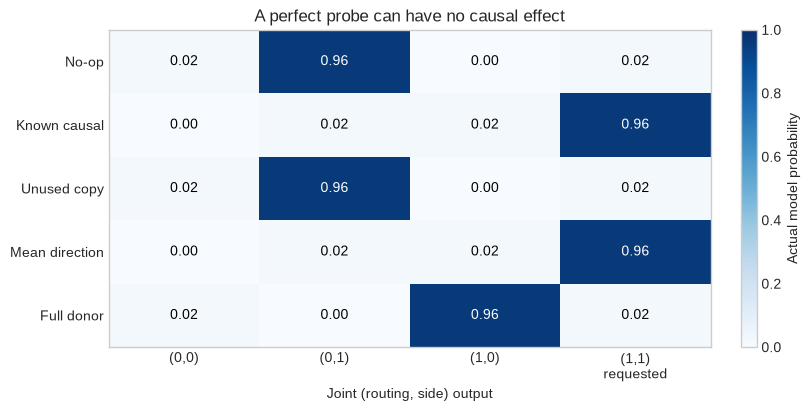

In [9]:
bases = {
    "No-op": rotation[:, :0],
    "Known causal": rotation[:, :1],
    "Unused copy": rotation[:, 2:3],
    "Mean direction": (rotation[:, :1] + rotation[:, 2:3]) / 2**0.5,
    "Full donor": rotation,
}
example_index = 6  # Base (0, 1), donor (1, 0): request (1, 1), class 3.
base = heldout["base"][example_index : example_index + 1]
source = heldout["source"][example_index : example_index + 1]
example_probabilities = t.stack(
    [
        (subspace_interchange(base, source, q) @ organism["readout"]).softmax(-1)[0]
        for q in bases.values()
    ]
)
fig, ax = plt.subplots(figsize=(8, 4), constrained_layout=True)
image = ax.imshow(example_probabilities.numpy(), cmap="Blues", vmin=0, vmax=1, aspect="auto")
ax.grid(False)
ax.set_xticks(range(4), ["(0,0)", "(0,1)", "(1,0)", "(1,1)" + chr(10) + "requested"])
ax.set_yticks(range(len(bases)), list(bases))
ax.set(
    xlabel="Joint (routing, side) output",
    title="A perfect probe can have no causal effect",
)
for i in range(len(bases)):
    for j in range(4):
        value = float(example_probabilities[i, j])
        ax.text(
            j,
            i,
            f"{value:.2f}",
            ha="center",
            va="center",
            color="white" if value > 0.5 else "black",
        )
fig.colorbar(image, ax=ax, label="Actual model probability")
fig.savefig(assets_dir / "das_exact_interchanges.png", dpi=160)
plt.show()


## Learn the intervention rather than the probe

DAS minimizes the disagreement induced by interventions. Here only the thin
alignment parameters are trainable; the encoder, readout and high-level model
stay fixed. A gradient still has to pass through the readout to the intervention.
Wrapping that continuation in `no_grad()` would sever the learning signal.

We use 300 full-batch Adam updates at learning rate .03, three initializations,
and a rank-one subspace. These are small-model development settings, not an
optimized recipe for GPT-2. The final update is returned. No held-out metric
chooses a checkpoint, and every seed is retained.


### Exercise 5 — Optimize a distributed alignment

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> You should spend 20 minutes on this exercise.
> ```

Initialize a thin trainable matrix with a local seeded generator. At every step, construct Q, patch the training base activations, run the frozen continuation and minimize counterfactual cross entropy. Record loss and IIA from step 0 through the final step.

<details><summary>Help</summary>

The optimizer should receive only the raw alignment matrix. Detach cached base/source activations, but keep autograd through Q, the swap and the model continuation. Zero the alignment gradient before backpropagating; check it is finite and nonempty.

</details>

<details><summary>Expected output</summary>

Training intervention loss falls, a fresh-nuisance test exceeds 98% IIA, and the model readout is bitwise unchanged. The test does not require recovering a unique planted vector.

</details>

<details><summary>Solution</summary>

```python
def fit_alignment(
    base: t.Tensor,
    source: t.Tensor,
    targets: t.Tensor,
    continue_model: Callable[[t.Tensor], t.Tensor],
    *,
    rank: int,
    steps: int = 200,
    learning_rate: float = 0.03,
    seed: int = 0,
) -> dict:
    """Optimize only a subspace using frozen activations and a frozen model tail.

    This small full-batch implementation is used by the exact organism. For a
    transformer, the continuation also needs each base prompt's untouched token
    positions. The caller must freeze model weights but retain autograd through
    the tail; inference_mode/no_grad around that tail would break DAS training.
    The returned alignment is the final step, not a test-selected checkpoint.
    """
    if not 1 <= rank <= base.shape[-1] or steps < 1 or learning_rate <= 0:
        raise ValueError("Use a feasible positive rank, step count and learning rate.")
    base, source = base.detach(), source.detach()
    generator = t.Generator(device=base.device).manual_seed(seed)
    raw = t.nn.Parameter(
        t.randn(base.shape[1], rank, dtype=base.dtype, device=base.device, generator=generator)
    )
    optimizer = t.optim.Adam([raw], lr=learning_rate)
    history = []
    for step in range(steps + 1):
        q = orthonormal_columns(raw)
        patched = subspace_interchange(base, source, q)
        logits = continue_model(patched)
        loss = intervention_loss(logits, targets)
        if not t.isfinite(loss):
            raise ValueError("The intervention objective became nonfinite.")
        history.append(
            {
                "step": step,
                "loss": float(loss.detach()),
                "iia": interchange_accuracy(logits.detach(), targets),
            }
        )
        if step == steps:
            break
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        if raw.grad is None or not t.isfinite(raw.grad).all():
            raise ValueError("A finite gradient must reach the alignment parameters.")
        optimizer.step()
    return {"basis": q.detach().clone(), "history": history}
```

</details>


In [10]:
def fit_alignment(
    base: t.Tensor,
    source: t.Tensor,
    targets: t.Tensor,
    continue_model: Callable[[t.Tensor], t.Tensor],
    *,
    rank: int,
    steps: int = 200,
    learning_rate: float = 0.03,
    seed: int = 0,
) -> dict:
    """Optimize only a subspace using frozen activations and a frozen model tail.

    This small full-batch implementation is used by the exact organism. For a
    transformer, the continuation also needs each base prompt's untouched token
    positions. The caller must freeze model weights but retain autograd through
    the tail; inference_mode/no_grad around that tail would break DAS training.
    The returned alignment is the final step, not a test-selected checkpoint.
    """
    if not 1 <= rank <= base.shape[-1] or steps < 1 or learning_rate <= 0:
        raise ValueError("Use a feasible positive rank, step count and learning rate.")
    base, source = base.detach(), source.detach()
    generator = t.Generator(device=base.device).manual_seed(seed)
    raw = t.nn.Parameter(
        t.randn(base.shape[1], rank, dtype=base.dtype, device=base.device, generator=generator)
    )
    optimizer = t.optim.Adam([raw], lr=learning_rate)
    history = []
    for step in range(steps + 1):
        q = orthonormal_columns(raw)
        patched = subspace_interchange(base, source, q)
        logits = continue_model(patched)
        loss = intervention_loss(logits, targets)
        if not t.isfinite(loss):
            raise ValueError("The intervention objective became nonfinite.")
        history.append(
            {
                "step": step,
                "loss": float(loss.detach()),
                "iia": interchange_accuracy(logits.detach(), targets),
            }
        )
        if step == steps:
            break
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        if raw.grad is None or not t.isfinite(raw.grad).all():
            raise ValueError("A finite gradient must reach the alignment parameters.")
        optimizer.step()
    return {"basis": q.detach().clone(), "history": history}



tests.test_alignment_optimization_changes_subspace_and_freezes_model(SimpleNamespace(**globals()))


Alignment training, held-out intervention and frozen-model tests passed!


In [11]:
target = high_level_output(
    high_level_interchange(train["base_variables"], train["source_variables"], (0,))
)
fits = {}
for seed in (0, 1, 2):
    for kind in ("DAS", "Shuffled targets"):
        targets = target
        if kind == "Shuffled targets":
            permutation = t.randperm(len(target), generator=t.Generator().manual_seed(400 + seed))
            targets = target[permutation]
        fitted = fit_alignment(
            train["base"],
            train["source"],
            targets,
            lambda h: h @ organism["readout"],
            rank=1,
            steps=300,
            learning_rate=0.03,
            seed=seed,
        )
        key = f"{kind}/seed{seed}"
        fits[key] = fitted
        bases[key] = fitted["basis"]
for draw in range(32):
    bases[f"Random/draw{draw}"] = orthonormal_columns(
        t.randn(8, 1, dtype=t.float64, generator=t.Generator().manual_seed(600 + draw))
    )
results = {name: evaluate_alignment(organism, heldout, q) for name, q in bases.items()}
assert t.equal(readout_before, organism["readout"]), "Only alignment parameters may change."
print("All six fits completed; all 32 random subspaces retained; model weights unchanged.")


All six fits completed; all 32 random subspaces retained; model weights unchanged.


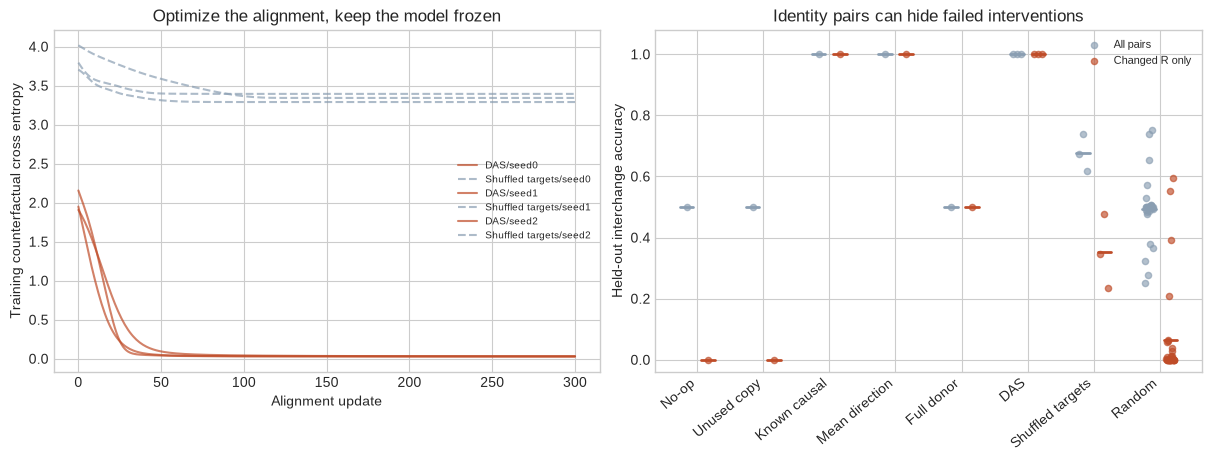

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
for name, fit in fits.items():
    shuffled = name.startswith("Shuffled")
    axes[0].plot(
        [r["step"] for r in fit["history"]],
        [r["loss"] for r in fit["history"]],
        color="#8a9eb2" if shuffled else "#bf4c28",
        alpha=0.7,
        linestyle="--" if shuffled else "-",
        label=name,
    )
axes[0].set(
    xlabel="Alignment update",
    ylabel="Training counterfactual cross entropy",
    title="Optimize the alignment, keep the model frozen",
)
axes[0].legend(fontsize=7)
groups = [
    "No-op",
    "Unused copy",
    "Known causal",
    "Mean direction",
    "Full donor",
    "DAS",
    "Shuffled targets",
    "Random",
]
for x, group in enumerate(groups):
    chosen = [r for name, r in results.items() if name == group or name.startswith(group + "/")]
    for offset, field, color, label in [
        (-0.16, "iia", "#8a9eb2", "All pairs"),
        (0.16, "changed_iia", "#bf4c28", "Changed R only"),
    ]:
        values = [r[field] for r in chosen]
        jitter = np.linspace(-0.06, 0.06, len(values)) if len(values) > 1 else np.zeros(1)
        axes[1].scatter(
            x + offset + jitter, values, c=color, s=20, alpha=0.65, label=label if x == 0 else None
        )
        axes[1].plot(
            [x + offset - 0.1, x + offset + 0.1], [np.mean(values)] * 2, color=color, linewidth=2
        )
axes[1].set_xticks(range(len(groups)), groups, rotation=40, ha="right")
axes[1].set(
    ylim=(-0.04, 1.08),
    ylabel="Held-out interchange accuracy",
    title="Identity pairs can hide failed interventions",
)
axes[1].legend(fontsize=8)
fig.savefig(assets_dir / "das_learning_and_controls.png", dpi=160)
plt.show()


<details><summary>Interpretation — did DAS discover the unique true feature?</summary>

All three learned subspaces reach 100% output agreement in this experiment, as
do the known causal subspace and the observational mean direction. The unused
copy gets 0% on changed-R pairs; random subspaces average about 6%, with the
strongest near 59%. All 32 remain visible. Shuffled supervision sometimes has
partial effects too: it is not guaranteed to do nothing.

The readout cannot distinguish every latent value that yields the same winning
class. Cross entropy can prefer an edit that pushes beyond the source's original
coordinate and raises confidence. Thus perfect answer agreement does not recover
the exact coordinate or a unique direction. Inspect the errors below rather than
concluding that a successful optimizer has uniquely identified the mechanism.

</details>


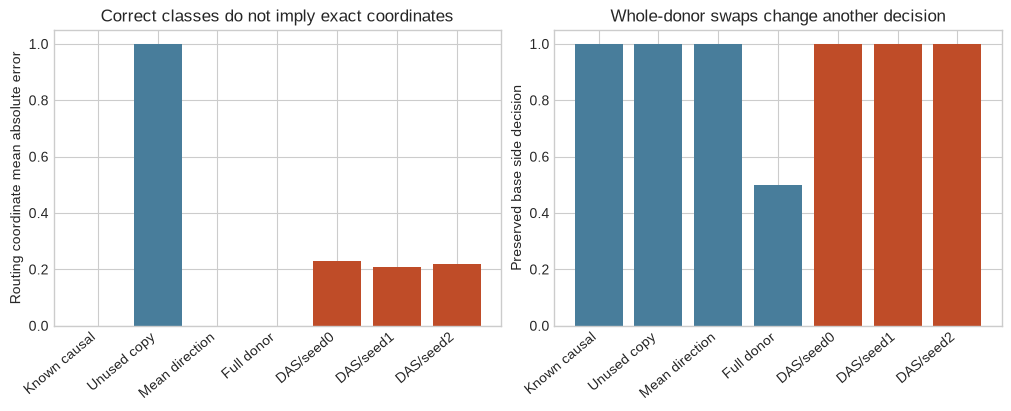

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), constrained_layout=True)
comparison_names = [
    "Known causal",
    "Unused copy",
    "Mean direction",
    "Full donor",
    "DAS/seed0",
    "DAS/seed1",
    "DAS/seed2",
]
for ax, metric, label in [
    (axes[0], "routing_coordinate_mae", "Routing coordinate mean absolute error"),
    (axes[1], "side_decision_accuracy", "Preserved base side decision"),
]:
    ax.bar(
        range(len(comparison_names)),
        [results[name][metric] for name in comparison_names],
        color=["#487d9b"] * 4 + ["#bf4c28"] * 3,
    )
    ax.set_xticks(range(len(comparison_names)), comparison_names, rotation=40, ha="right")
    ax.set(ylabel=label)
axes[0].set_title("Correct classes do not imply exact coordinates")
axes[1].set_title("Whole-donor swaps change another decision")
axes[1].set_ylim(0, 1.05)
fig.savefig(assets_dir / "das_coordinate_and_specificity.png", dpi=160)
plt.show()


## Try It Yourself — move from an unused feature toward a used one

Vary the angle below. At zero degrees the intervention targets only the unused
copy; at 90 degrees it targets the known causal feature. Before running, predict
whether IIA should increase smoothly. Does confidence or coordinate error tell
you something that a hard 0/1 accuracy hides?

Then switch the high-level variable in the first exercise to `(1,)` and build
the corresponding intervention using `rotation[:, 1:2]`. The desired output must
preserve the base routing decision. Merely changing the target labels after a
routing swap is not the same experiment.


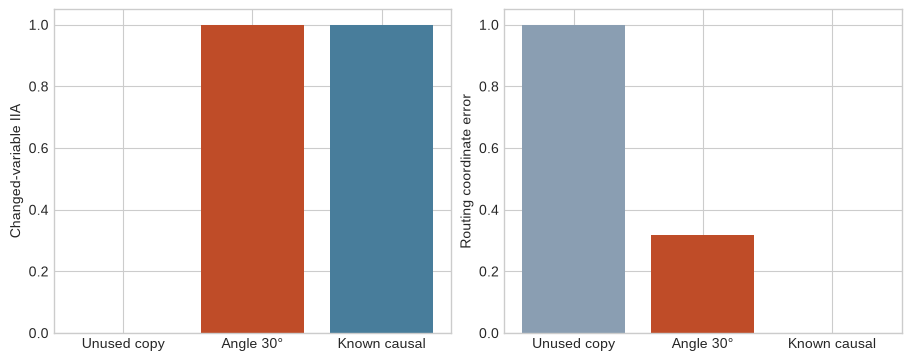

In [14]:
PLAY_ANGLE_DEGREES = 30
angle = t.tensor(PLAY_ANGLE_DEGREES * np.pi / 180, dtype=t.float64)
play_basis = angle.cos() * rotation[:, 2:3] + angle.sin() * rotation[:, :1]
play_results = {
    "Unused copy": results["Unused copy"],
    f"Angle {PLAY_ANGLE_DEGREES}°": evaluate_alignment(organism, heldout, play_basis),
    "Known causal": results["Known causal"],
}
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5), constrained_layout=True)
for ax, metric, label in [
    (axes[0], "changed_iia", "Changed-variable IIA"),
    (axes[1], "routing_coordinate_mae", "Routing coordinate error"),
]:
    ax.bar(
        list(play_results),
        [r[metric] for r in play_results.values()],
        color=["#8a9eb2", "#bf4c28", "#487d9b"],
    )
    ax.set(ylabel=label)
axes[0].set_ylim(0, 1.05)
fig.savefig(assets_dir / "das_angle_play.png", dpi=160)
plt.show()


# 4️⃣ Intervening on a role in GPT-2

The exact model let us inspect the whole computation. We now have a less
cooperative model: GPT-2, with 12 transformer blocks and 768 residual coordinates.
We will keep its weights frozen and learn a small subspace to interchange.

Consider this pair of prompts:

> **Base:** When Mary and John went to the store, John gave a book to ...
>
> **Source:** When Tom and James went to the store, Tom gave a book to ...

The base answer is **Mary**. The source answer is **James**. Our intervention's
answer should be **John**. Why? We want to copy *which of the first two people
repeats*, preserving the base names. Copying the source's answer would solve a
different task.

Write the first two names as $A, B$, and the repeated-name role as
$R \in \{0,1\}$. Our high-level model is

$$Y(A,B,R) = \begin{cases} B & R=0 \\ A & R=1. \end{cases}$$

The high-level interchange sets $R_b \leftarrow R_s$. It predicts
$Y(A_b,B_b,R_s)$, while an ordinary source-prompt forward predicts
$Y(A_s,B_s,R_s)$. These need not agree. This distinction is what makes the
cross-name control informative.

### Exercise 6 — Specify the name-role counterfactual

> ```yaml
> Difficulty: 🔴⚪⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> You should spend 5–10 minutes on this exercise.
> ```

Implement `role_interchange_targets`. `base_names` contains two vocabulary token
IDs per example, in first-occurrence order. `source_roles` contains 0 or 1. Return
one target vocabulary ID per intervention. Do not use the source's name IDs.

<details><summary>Help — which column do you select?</summary>

When source R is zero, the first base name repeats, so the answer is the second
base name: column one. When source R is one, select column zero. This is a gather
operation with column indices `1 - source_roles`.

</details>

<details><summary>Expected output</summary>

The four test interventions return `[29, 11, 53, 37]`. Changing the source role selects the other base name while retaining the base token IDs.

</details>

<details><summary>Solution</summary>

```python
def role_interchange_targets(base_names: t.Tensor, source_roles: t.Tensor) -> t.Tensor:
    if base_names.ndim != 2 or base_names.shape[1] != 2:
        raise ValueError("Use two base name token IDs per example.")
    if source_roles.shape != (len(base_names),) or not t.all(
        (source_roles == 0) | (source_roles == 1)
    ):
        raise ValueError("Use one binary source role per example.")
    return base_names.gather(1, (1 - source_roles.long())[:, None]).squeeze(1)
```

</details>


In [15]:
def role_interchange_targets(base_names: t.Tensor, source_roles: t.Tensor) -> t.Tensor:
    if base_names.ndim != 2 or base_names.shape[1] != 2:
        raise ValueError("Use two base name token IDs per example.")
    if source_roles.shape != (len(base_names),) or not t.all(
        (source_roles == 0) | (source_roles == 1)
    ):
        raise ValueError("Use one binary source role per example.")
    return base_names.gather(1, (1 - source_roles.long())[:, None]).squeeze(1)



base_names = t.tensor([[11, 29], [11, 29], [37, 53], [37, 53]])
source_roles = t.tensor([0, 1, 0, 1])
t.testing.assert_close(
    role_interchange_targets(base_names, source_roles), t.tensor([29, 11, 53, 37])
)
print("Both role values preserve the recipient's names. Counterfactual tests passed!")


Both role values preserve the recipient's names. Counterfactual tests passed!


## The data and the frozen model

We use 72 training prompts and 48 development prompts. Every base has four
interventions: a donor with the same names or completely different names, with
each possible repeated role. The exact same-prompt case is an identity control;
we will keep it separate from changed-role accuracy. The final set has 96
prompts with new templates and name pairings. We will run it only after choosing
our layer and rank on development data.

Names must each occupy one space-prefixed GPT-2 token. A token-offset check
locates the repeated subject exactly. We use left padding and explicit position
IDs so unequal prompt lengths do not shift the model's position embeddings.
These are provided data and tokenization helpers; the interventions and fitting
methods remain yours to implement.

The checkpoint is pinned and loaded from the local Hugging Face cache. If it is
not cached, download `gpt2` at revision
`607a30d783dfa663caf39e06633721c8d4cfcd7e` before continuing. The experiment runs
on CPU in float32; freezing weights does not remove the need for gradients
through the layers *after* an intervention.


In [16]:
from transformers import AutoModelForCausalLM, AutoTokenizer
from chapter11_representation_geometry.exercises.part3_causal_abstraction_das import (
    das_ioi_data as ioi_data,
    das_training_tests as training_tests,
    das_native_tests as native_tests,
)
from chapter11_representation_geometry.exercises.part3_causal_abstraction_das.das_native import (
    capture_native,
    require_frozen,
)

tokenizer = AutoTokenizer.from_pretrained(
    ioi_data.MODEL_ID, revision=ioi_data.REVISION, local_files_only=True
)
tokenizer.pad_token = tokenizer.eos_token
tokenizer.padding_side = "left"
gpt2 = (
    AutoModelForCausalLM.from_pretrained(
        ioi_data.MODEL_ID,
        revision=ioi_data.REVISION,
        local_files_only=True,
        dtype=t.float32,
        attn_implementation="eager",
    )
    .cpu()
    .eval()
)
gpt2.requires_grad_(False)
t.set_num_threads(4)
train_rows = ioi_data.prompt_rows("train")
dev_rows = ioi_data.prompt_rows("development")
train_interventions = ioi_data.interchange_pairs(train_rows)
dev_interventions = ioi_data.interchange_pairs(dev_rows)
name_ids = ioi_data.name_token_ids(tokenizer, train_rows)
train_cache = capture_native(gpt2, tokenizer, train_rows)
dev_cache = capture_native(gpt2, tokenizer, dev_rows)

for rows, interventions in [(train_rows, train_interventions), (dev_rows, dev_interventions)]:
    names = t.tensor(
        [[name_ids[rows[p["base"]]["a"]], name_ids[rows[p["base"]]["b"]]] for p in interventions]
    )
    source_roles = t.tensor([rows[p["source"]]["role"] for p in interventions])
    expected = t.tensor([name_ids[p["target"]] for p in interventions])
    t.testing.assert_close(role_interchange_targets(names, source_roles), expected)
print(
    "All 480 training/development counterfactuals checked; final model evaluation remains closed."
)


W0906 15:58:12.632000 1940791 torch/utils/_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


W0906 15:58:12.642000 1940791 torch/utils/_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

All 480 training/development counterfactuals checked; final model evaluation remains closed.


### Exercise 7 — Resume the native transformer with gradients

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵🔵
> You should spend 15–25 minutes on this exercise.
> ```

Recomputing the layers before an intervention cannot help optimize its subspace:
those layers are frozen, and the intervention occurs after them. We can cache
their output and run the remaining native blocks. The cache contains the
**complete base sequence** at each boundary and the exact native attention mask.
Copying a donor's whole sequence would erase the base computation we want to
preserve.

Implement `continue_native`. Select the requested recipient rows, clone their
cached hidden states, replace one vector per row, and run GPT-2 blocks from
`layer` onward. Finish with the final layer norm and vocabulary head. The
`subject` site is the repeated name; `end` is the last prompt token, where GPT-2
predicts the answer. Neither may point into padding.

Do not wrap this function in `no_grad` or `inference_mode`. Only the cached
prefix and model weights are detached. Assignment into a cloned tensor should
keep an autograd path from the replacement to the final loss.

<details><summary>Help — what must stay attached to the computation graph?</summary>

The base cache can be detached, because it is constant. `replacement` depends
on the learned basis, so it must stay attached. PyTorch records slice assignment
into the clone and propagates the tail's gradients back to the assigned values.
The model's frozen parameters can still participate in this differentiable
computation: `requires_grad=False` prevents their own gradients, not gradients
with respect to their inputs.

</details>

<details><summary>Expected output</summary>

Both continuation paths agree on logits and gradients at all three tiny-model boundaries and both token positions. You should see `Native continuation logits and gradient tests passed!`. The next cell additionally checks the pretrained model.

</details>

<details><summary>Solution</summary>

```python
def continue_native(model, cache, layer, indices, replacement, mode="subject"):
    """Resume native blocks after changing one residual vector in each base.

    Slice assignment into a clone is differentiable with respect to replacement.
    All other token positions retain their cached recipient activations.
    """
    require_frozen(model)
    hidden = cache.hidden[layer][indices].clone()
    if replacement.shape != (len(indices), hidden.shape[-1]):
        raise ValueError("Supply one replacement vector per selected recipient.")
    hidden[t.arange(len(indices)), cache.positions(mode)[indices]] = replacement
    for block in model.transformer.h[layer:]:
        hidden = block(
            hidden,
            None,
            cache.causal_mask[indices],
            None,
            encoder_attention_mask=None,
            use_cache=False,
            position_ids=cache.tokens["position_ids"][indices],
        )
    return model.lm_head(model.transformer.ln_f(hidden)[:, -1])
```

</details>


In [17]:
def continue_native(model, cache, layer, indices, replacement, mode="subject"):
    """Resume native blocks after changing one residual vector in each base.

    Slice assignment into a clone is differentiable with respect to replacement.
    All other token positions retain their cached recipient activations.
    """
    require_frozen(model)
    hidden = cache.hidden[layer][indices].clone()
    if replacement.shape != (len(indices), hidden.shape[-1]):
        raise ValueError("Supply one replacement vector per selected recipient.")
    hidden[t.arange(len(indices)), cache.positions(mode)[indices]] = replacement
    for block in model.transformer.h[layer:]:
        hidden = block(
            hidden,
            None,
            cache.causal_mask[indices],
            None,
            encoder_attention_mask=None,
            use_cache=False,
            position_ids=cache.tokens["position_ids"][indices],
        )
    return model.lm_head(model.transformer.ln_f(hidden)[:, -1])



native_tests.test_cached_native_logits_and_gradients(continue_native)


[transformers] Model config: bos_token_id must be `None` or an integer within the vocabulary (between 0 and 30), got 50256. This may result in unexpected behavior.


[transformers] Model config: eos_token_id must be `None` or an integer within the vocabulary (between 0 and 30), got 50256. This may result in unexpected behavior.


Native continuation logits and gradient tests passed!


## Check the path on the pretrained model too

A cache is useful only if it reproduces the native computation. The next cell
compares your continuation with a full-forward intervention hook at all six
sites. It also compares actual gradients on GPT-2. Small FP32 matrix-multiply
differences are recorded; they must not grow into changed token distributions.


In [18]:
from chapter11_representation_geometry.exercises.part3_causal_abstraction_das.das_native import (
    full_forward_intervention,
)

native_path_checks = []
check_indices = t.tensor([0, 1, 24, 25])
for layer in (3, 6, 9):
    for mode in ("subject", "end"):
        activation = dev_cache.activations(layer, mode)[check_indices]
        for label, replacement in [("No-op", activation), ("Whole donor", activation.flip(0))]:
            with t.no_grad():
                own_logits = continue_native(
                    gpt2, dev_cache, layer, check_indices, replacement, mode
                )
                oracle_logits = full_forward_intervention(
                    gpt2, dev_cache, layer, check_indices, replacement, mode
                )
            logit_error = float((own_logits - oracle_logits).abs().max())
            probability_error = float(
                (own_logits.softmax(-1) - oracle_logits.softmax(-1)).abs().max()
            )
            assert logit_error < 3e-4 and probability_error < 1e-5
            native_path_checks.append(
                dict(
                    layer=layer,
                    position=mode,
                    intervention=label,
                    max_logit_error=logit_error,
                    max_probability_error=probability_error,
                )
            )
replacement = dev_cache.activations(9, "end")[check_indices].flip(0).clone().requires_grad_()
check_targets = t.tensor([name_ids[dev_rows[i]["answer"]] for i in check_indices])
own_logits = continue_native(gpt2, dev_cache, 9, check_indices, replacement, "end")
oracle_logits = full_forward_intervention(gpt2, dev_cache, 9, check_indices, replacement, "end")
own_gradient = t.autograd.grad(intervention_loss(own_logits, check_targets), replacement)[0]
oracle_gradient = t.autograd.grad(
    t.nn.functional.cross_entropy(oracle_logits, check_targets), replacement
)[0]
t.testing.assert_close(own_gradient, oracle_gradient, atol=1e-5, rtol=1e-4)
assert own_gradient.norm() > 0
print("All 12 pretrained path comparisons and the native gradient check passed.")
print("Largest FP32 logit difference:", max(row["max_logit_error"] for row in native_path_checks))


All 12 pretrained path comparisons and the native gradient check passed.
Largest FP32 logit difference: 9.1552734375e-05


The immediate test uses a small, explicitly random GPT-2 to check native-library
semantics quickly. It is not evidence of a learned role. The pretrained experiment
also needs native hook parity, unchanged model weights, and meaningful held-out
interventions. A gradient test by itself establishes none of those behaviors.

# 5️⃣ A probe and an intervention can disagree

An observational role probe uses examples `(activation, R)` and asks whether R
can be predicted. DAS uses `(base, source, counterfactual answer)` and asks
whether copying a subspace implements the requested change. The labels describe
related variables, but the learning problems are different.

### Exercise 8 — Fit an observational baseline

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> You should spend 10–15 minutes on this exercise.
> ```

Fit a centered ridge regression from activations to `2 * R - 1`. Normalize its
coefficient vector to get a rank-one intervention basis. Return the unnormalized
coefficient and means too, so we can evaluate ordinary prediction accuracy.
Use the training data only.

With centered activations X, target y and n examples, the coefficient is

$$w = X^\top (XX^\top + n\lambda I)^{-1}(y - \bar y).$$

The dual form solves an n × n system instead of a 768 × 768 system. It is the
same ridge objective, not a causal constraint. A direction can be an excellent
classifier and still be an ineffective intervention.

<details><summary>Help — how do you predict on new activations?</summary>

Subtract the *training* activation mean, multiply by the unnormalized coefficient,
and add the training target mean. Threshold at zero for R. Do not refit a mean
or coefficient on the evaluation split. For an interchange, normalize the
coefficient and pass that basis to `subspace_interchange` instead.

</details>

<details><summary>Expected output</summary>

The sample-space solve agrees with an independent feature-space ridge solution, and shifting all activations leaves the coefficient unchanged. You should see `Observational probe tests passed!`.

</details>

<details><summary>Solution</summary>

```python
def fit_role_probe(activations: t.Tensor, roles: t.Tensor, ridge: float = 0.1) -> dict:
    """Observational ridge probe; its coefficient defines a rank-one edit.

    Fit only training activations to predict R in {-1, +1}. Solving in sample
    space avoids a width × width inverse. This is a predictive baseline, with
    no intervention loss. It need not identify a causally effective subspace.
    """
    if activations.ndim != 2 or roles.shape != (len(activations),) or ridge <= 0:
        raise ValueError("Use one binary role label per activation and positive ridge.")
    if not t.all((roles == 0) | (roles == 1)):
        raise ValueError("Role labels must be zero or one.")
    x_mean = activations.mean(0)
    target = roles.to(activations) * 2 - 1
    y_mean = target.mean()
    centered = activations - x_mean
    gram = centered @ centered.T
    dual = t.linalg.solve(
        gram
        + ridge
        * len(activations)
        * t.eye(len(activations), dtype=activations.dtype, device=activations.device),
        target - y_mean,
    )
    coefficient = centered.T @ dual
    if coefficient.norm() < 1e-8:
        raise ValueError("The fitted probe has no direction.")
    return dict(
        basis=(coefficient / coefficient.norm())[:, None],
        coefficient=coefficient,
        x_mean=x_mean,
        y_mean=y_mean,
    )
```

</details>


In [19]:
def fit_role_probe(activations: t.Tensor, roles: t.Tensor, ridge: float = 0.1) -> dict:
    """Observational ridge probe; its coefficient defines a rank-one edit.

    Fit only training activations to predict R in {-1, +1}. Solving in sample
    space avoids a width × width inverse. This is a predictive baseline, with
    no intervention loss. It need not identify a causally effective subspace.
    """
    if activations.ndim != 2 or roles.shape != (len(activations),) or ridge <= 0:
        raise ValueError("Use one binary role label per activation and positive ridge.")
    if not t.all((roles == 0) | (roles == 1)):
        raise ValueError("Role labels must be zero or one.")
    x_mean = activations.mean(0)
    target = roles.to(activations) * 2 - 1
    y_mean = target.mean()
    centered = activations - x_mean
    gram = centered @ centered.T
    dual = t.linalg.solve(
        gram
        + ridge
        * len(activations)
        * t.eye(len(activations), dtype=activations.dtype, device=activations.device),
        target - y_mean,
    )
    coefficient = centered.T @ dual
    if coefficient.norm() < 1e-8:
        raise ValueError("The fitted probe has no direction.")
    return dict(
        basis=(coefficient / coefficient.norm())[:, None],
        coefficient=coefficient,
        x_mean=x_mean,
        y_mean=y_mean,
    )



training_tests.test_role_probe(fit_role_probe)


Observational probe tests passed!


### Exercise 9 — Train a context-aware alignment

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵🔵
> You should spend 20–30 minutes on this exercise.
> ```

Adapt the exact model's optimizer to minibatches. Every intervention has a base
prompt whose *other token positions* must remain unchanged. The continuation
therefore needs both the intervention indices and replacement vectors:
`continue_model(pair_indices, replacement)`.

Use one trainable matrix with shape `[width, rank]`, initialize it with standard
deviation `1 / sqrt(width)`, and obtain an orthonormal basis with reduced QR on
every step. Shuffle the full set of intervention pairs each epoch, including the
last smaller batch. Optimize full-vocabulary cross entropy. Return the final
basis and every minibatch loss; do not choose a checkpoint using final data.

<details><summary>Help — what belongs in the optimizer?</summary>

Only the raw alignment matrix. Cached base/source activations are constants and
GPT-2's parameters have `requires_grad=False`. The sequence is QR → subspace
interchange → frozen native continuation → cross entropy → backward → Adam.
Zero the alignment gradient before each backward pass. Check that the gradient
exists and is finite; a detached replacement can otherwise look like a training
loop while learning nothing.

A loss recorded on a changing minibatch is noisy. It is not a held-out curve.
Keep that distinction in your plot labels and evaluate all development pairs
separately after training.

</details>

<details><summary>Expected output</summary>

The first epoch visits all 64 test pairs once, including a final four-example minibatch. The fitted subspace exceeds 97% changed-role accuracy on fresh exact-model nuisances, with the readout unchanged. You should see `Minibatch alignment and recipient-context tests passed!`.

</details>

<details><summary>Solution</summary>

```python
def fit_minibatch_alignment(
    base: t.Tensor,
    source: t.Tensor,
    targets: t.Tensor,
    continue_model: Callable[[t.Tensor, t.Tensor], t.Tensor],
    *,
    rank: int,
    steps: int = 120,
    batch_size: int = 16,
    learning_rate: float = 0.01,
    seed: int = 0,
) -> dict:
    """DAS with recipient-context-aware minibatches and a thin QR basis.

    continue_model(pair_indices, replacements) resumes the frozen recipient
    computation. The only optimizer parameter is raw, a width × rank matrix.
    All pairs are visited once per shuffled epoch. Save the final iterate;
    training losses below are minibatch losses, not held-out measurements.
    """
    if base.ndim != 2 or source.shape != base.shape or targets.shape != (len(base),):
        raise ValueError("Use paired activation matrices and one target per pair.")
    if not 1 <= rank <= base.shape[1] or min(steps, batch_size) < 1 or learning_rate <= 0:
        raise ValueError("Rank, training steps, batch size and learning rate must be positive.")
    base, source = base.detach(), source.detach()
    generator = t.Generator(device=base.device).manual_seed(seed)
    raw = t.nn.Parameter(
        t.randn(base.shape[1], rank, dtype=base.dtype, device=base.device, generator=generator)
        / base.shape[1] ** 0.5
    )
    optimizer = t.optim.Adam([raw], lr=learning_rate)
    history, order, offset = [], t.empty(0, dtype=t.long), 0
    for step in range(steps):
        if offset >= len(order):
            order = t.randperm(len(base), generator=generator, device=base.device)
            offset = 0
        indices = order[offset : offset + batch_size]
        offset += batch_size
        basis = orthonormal_columns(raw)
        replacement = subspace_interchange(base[indices], source[indices], basis)
        logits = continue_model(indices, replacement)
        loss = intervention_loss(logits, targets[indices])
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        if not t.isfinite(loss) or raw.grad is None or not t.isfinite(raw.grad).all():
            raise ValueError("A finite intervention gradient must reach the alignment.")
        history.append(
            dict(
                step=step,
                loss=float(loss.detach()),
                gradient_norm=float(raw.grad.norm()),
                batch_size=len(indices),
                iia=float((logits.detach().argmax(-1) == targets[indices]).float().mean()),
            )
        )
        optimizer.step()
    return dict(basis=orthonormal_columns(raw).detach().clone(), history=history)
```

</details>


In [20]:
def fit_minibatch_alignment(
    base: t.Tensor,
    source: t.Tensor,
    targets: t.Tensor,
    continue_model: Callable[[t.Tensor, t.Tensor], t.Tensor],
    *,
    rank: int,
    steps: int = 120,
    batch_size: int = 16,
    learning_rate: float = 0.01,
    seed: int = 0,
) -> dict:
    """DAS with recipient-context-aware minibatches and a thin QR basis.

    continue_model(pair_indices, replacements) resumes the frozen recipient
    computation. The only optimizer parameter is raw, a width × rank matrix.
    All pairs are visited once per shuffled epoch. Save the final iterate;
    training losses below are minibatch losses, not held-out measurements.
    """
    if base.ndim != 2 or source.shape != base.shape or targets.shape != (len(base),):
        raise ValueError("Use paired activation matrices and one target per pair.")
    if not 1 <= rank <= base.shape[1] or min(steps, batch_size) < 1 or learning_rate <= 0:
        raise ValueError("Rank, training steps, batch size and learning rate must be positive.")
    base, source = base.detach(), source.detach()
    generator = t.Generator(device=base.device).manual_seed(seed)
    raw = t.nn.Parameter(
        t.randn(base.shape[1], rank, dtype=base.dtype, device=base.device, generator=generator)
        / base.shape[1] ** 0.5
    )
    optimizer = t.optim.Adam([raw], lr=learning_rate)
    history, order, offset = [], t.empty(0, dtype=t.long), 0
    for step in range(steps):
        if offset >= len(order):
            order = t.randperm(len(base), generator=generator, device=base.device)
            offset = 0
        indices = order[offset : offset + batch_size]
        offset += batch_size
        basis = orthonormal_columns(raw)
        replacement = subspace_interchange(base[indices], source[indices], basis)
        logits = continue_model(indices, replacement)
        loss = intervention_loss(logits, targets[indices])
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        if not t.isfinite(loss) or raw.grad is None or not t.isfinite(raw.grad).all():
            raise ValueError("A finite intervention gradient must reach the alignment.")
        history.append(
            dict(
                step=step,
                loss=float(loss.detach()),
                gradient_norm=float(raw.grad.norm()),
                batch_size=len(indices),
                iia=float((logits.detach().argmax(-1) == targets[indices]).float().mean()),
            )
        )
        optimizer.step()
    return dict(basis=orthonormal_columns(raw).detach().clone(), history=history)



training_tests.test_minibatch_alignment(fit_minibatch_alignment)


Minibatch alignment and recipient-context tests passed!


## Evaluate the interventions you actually asked for

The following short loop batches native forwards. It uses your interchange and
continuation functions. A whole-position donor is also evaluated: it can change
more information than the requested role. Always compare against the
counterfactual answer derived from the *base* names.

For each condition we retain all full-vocabulary logits. `native_metrics` reports
unconditional IIA first, then a separate diagnostic subset where the base and
explicit counterfactual prompts are both natively correct. The latter answers a
useful question about alignment failures, but it must not silently replace the
full denominator. Identity pairs and changed-role pairs are also separate.


In [21]:
from chapter11_representation_geometry.exercises.part3_causal_abstraction_das.run_das_screen import (
    summarize as native_metrics,
)
from chapter11_representation_geometry.exercises.part3_causal_abstraction_das.run_native_development import (
    weight_digest,
)


def evaluate_native_pairs(cache, interventions, layer, mode, basis=None, whole_donor=False):
    activation = cache.activations(layer, mode)
    all_logits = []
    with t.no_grad():
        for start in range(0, len(interventions), 24):
            batch = interventions[start : start + 24]
            base = t.tensor([p["base"] for p in batch])
            source = t.tensor([p["source"] for p in batch])
            replacement = (
                activation[source]
                if whole_donor
                else subspace_interchange(activation[base], activation[source], basis)
            )
            all_logits.append(continue_native(gpt2, cache, layer, base, replacement, mode))
    return t.cat(all_logits)


train_base_indices = t.tensor([p["base"] for p in train_interventions])
train_source_indices = t.tensor([p["source"] for p in train_interventions])
train_names = t.tensor(
    [
        [name_ids[train_rows[p["base"]]["a"]], name_ids[train_rows[p["base"]]["b"]]]
        for p in train_interventions
    ]
)
train_roles = t.tensor([train_rows[p["source"]]["role"] for p in train_interventions])
train_targets = role_interchange_targets(train_names, train_roles)


def train_native_alignment(layer, mode, rank, seed, steps, shuffled=False):
    activation = train_cache.activations(layer, mode)
    targets = train_targets
    if shuffled:
        permutation = t.randperm(len(targets), generator=t.Generator().manual_seed(400 + seed))
        targets = targets[permutation]

    def tail(pair_indices, replacement):
        return continue_native(
            gpt2, train_cache, layer, train_base_indices[pair_indices], replacement, mode
        )

    return fit_minibatch_alignment(
        activation[train_base_indices],
        activation[train_source_indices],
        targets,
        tail,
        rank=rank,
        seed=seed,
        steps=steps,
        batch_size=16,
        learning_rate=0.01,
    )


native_weights_before = weight_digest(gpt2)
dev_base_indices = t.tensor([p["base"] for p in dev_interventions])
dev_noop = native_metrics(
    dev_cache.logits[dev_base_indices], dev_interventions, dev_rows, name_ids, dev_cache.logits
)
print(f"Native development prompt accuracy: {dev_noop['native_prompt_accuracy']:.1%}")
print(
    f"No intervention, changed role: {dev_noop['cross_changed']['iia']:.1%} of {dev_noop['cross_changed']['n']} pairs"
)


Native development prompt accuracy: 89.6%
No intervention, changed role: 0.0% of 48 pairs


## Find where the intervention works

Before running, predict which site should be useful. At the repeated subject,
the model can compare its current name to earlier names. At the final token,
later blocks have information about the answer. A role can be easy to *read*
before it is easy to *change*, or easy to change at one site after its effects
have already propagated away from another site.

We compare six sites, using one dimension, seed 0 and 120 updates. The next cell
trains all six candidates on the same training pairs. This is development
selection: it does not touch the final set. Retain every candidate, including
sites at which nothing useful happens.


In [22]:
site_results = []
site_fits = {}
site_logits = {}
for layer in (3, 6, 9):
    for mode in ("subject", "end"):
        activation = train_cache.activations(layer, mode)
        roles = t.tensor([row["role"] for row in train_rows])
        probe = fit_role_probe(activation, roles)
        predicted_role = (
            (dev_cache.activations(layer, mode) - probe["x_mean"]) @ probe["coefficient"]
            + probe["y_mean"]
        ) > 0
        probe_accuracy = float(
            predicted_role.eq(t.tensor([r["role"] for r in dev_rows])).float().mean()
        )
        fit = train_native_alignment(layer, mode, rank=1, seed=0, steps=120)
        site_fits[layer, mode] = fit
        for method, basis, whole in [
            ("Probe", probe["basis"], False),
            ("DAS", fit["basis"], False),
            ("Whole donor", None, True),
        ]:
            logits = evaluate_native_pairs(dev_cache, dev_interventions, layer, mode, basis, whole)
            site_logits[layer, mode, method] = logits
            metrics = native_metrics(
                logits, dev_interventions, dev_rows, name_ids, dev_cache.logits
            )
            site_results.append(
                dict(
                    layer=layer,
                    position=mode,
                    method=method,
                    metrics=metrics,
                    probe_accuracy=probe_accuracy,
                )
            )
        print(f"Finished block {layer} input / {mode}.")


Finished block 3 input / subject.


Finished block 3 input / end.


Finished block 6 input / subject.


Finished block 6 input / end.


Finished block 9 input / subject.


Finished block 9 input / end.


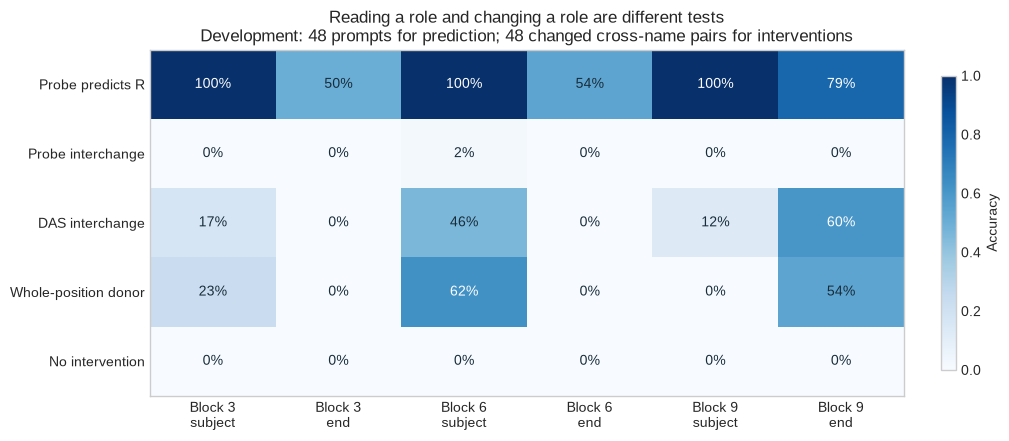

Selected on development: 9 end


In [23]:
sites = [(layer, mode) for layer in (3, 6, 9) for mode in ("subject", "end")]
lookup = {(r["layer"], r["position"], r["method"]): r for r in site_results}
matrix = np.array(
    [
        [lookup[layer, mode, "Probe"]["probe_accuracy"] for layer, mode in sites],
        *[
            [
                lookup[layer, mode, method]["metrics"]["cross_changed"]["iia"]
                for layer, mode in sites
            ]
            for method in ("Probe", "DAS", "Whole donor")
        ],
        [dev_noop["cross_changed"]["iia"]] * len(sites),
    ]
)
fig, ax = plt.subplots(figsize=(10, 4.3), constrained_layout=True)
im = ax.imshow(matrix, vmin=0, vmax=1, cmap="Blues", aspect="auto")
for row in range(matrix.shape[0]):
    for col in range(matrix.shape[1]):
        ax.text(
            col,
            row,
            f"{matrix[row, col]:.0%}",
            ha="center",
            va="center",
            color="white" if matrix[row, col] > 0.55 else "#182c3a",
        )
ax.set_xticks(range(len(sites)), [f"Block {layer}" + chr(10) + mode for layer, mode in sites])
ax.set_yticks(
    range(5),
    [
        "Probe predicts R",
        "Probe interchange",
        "DAS interchange",
        "Whole-position donor",
        "No intervention",
    ],
)
ax.grid(False)
ax.set_title(
    "Reading a role and changing a role are different tests"
    + chr(10)
    + "Development: 48 prompts for prediction; 48 changed cross-name pairs for interventions"
)
fig.colorbar(
    im,
    ax=ax,
    label="Accuracy",
    shrink=0.85,
)
fig.savefig(assets_dir / "das_native_site_comparison.png", dpi=160)
plt.show()

ranked_sites = sorted(
    [r for r in site_results if r["method"] == "DAS"],
    key=lambda r: (
        -r["metrics"]["cross_changed"]["iia"],
        -r["metrics"]["cross_changed_target_probability"],
        r["layer"],
        r["position"] != "subject",
    ),
)
SELECTED_LAYER, SELECTED_POSITION = ranked_sites[0]["layer"], ranked_sites[0]["position"]
print("Selected on development:", SELECTED_LAYER, SELECTED_POSITION)


<details><summary>Interpretation — a perfect probe with an ineffective edit</summary>

The repeated-subject probes can predict R perfectly on these development
prompts. Their normalized coefficient directions still perform few or no
correct cross-name role changes. Classification constrains a readout of the
activation; it does not constrain the downstream model's response to replacing
that direction.

The six-site screen favors the final token before block 9. The subject at block
6 also has a substantial role-changing effect, while the early final-token
sites are weak. This is a result on this prompt distribution and objective,
not a statement that every representation of the role lives at one location.

</details>

## Try It Yourself — change one site before changing the story

Set `PLAY_LAYER` and `PLAY_POSITION`, rerun this small training experiment, and
compare it to the whole-donor and no-intervention controls. Keep the data and
rank fixed. Which result would persuade you that a site is useful for reading
the role, changing it, or both? This play uses development data only and does
not change the frozen final-evaluation recipe.


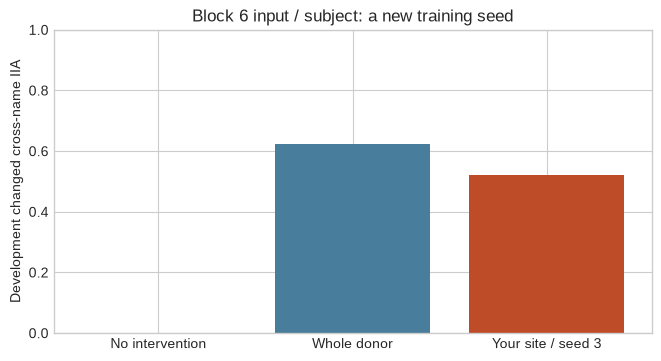

In [24]:
PLAY_LAYER, PLAY_POSITION = 6, "subject"
play_fit = train_native_alignment(PLAY_LAYER, PLAY_POSITION, rank=1, seed=3, steps=120)
play_logits = evaluate_native_pairs(
    dev_cache, dev_interventions, PLAY_LAYER, PLAY_POSITION, play_fit["basis"]
)
play_metric = native_metrics(play_logits, dev_interventions, dev_rows, name_ids, dev_cache.logits)
whole_metric = lookup[PLAY_LAYER, PLAY_POSITION, "Whole donor"]["metrics"]
fig, ax = plt.subplots(figsize=(6.5, 3.5), constrained_layout=True)
ax.bar(
    ["No intervention", "Whole donor", "Your site / seed 3"],
    [
        dev_noop["cross_changed"]["iia"],
        whole_metric["cross_changed"]["iia"],
        play_metric["cross_changed"]["iia"],
    ],
    color=["#8a9eb2", "#487d9b", "#bf4c28"],
)
ax.set(
    ylim=(0, 1),
    ylabel="Development changed cross-name IIA",
    title=f"Block {PLAY_LAYER} input / {PLAY_POSITION}: a new training seed",
)
fig.savefig(assets_dir / "das_native_site_play.png", dpi=160)
plt.show()


## How many dimensions should we copy?

At the selected site, compare ranks 1, 2, 4 and 8 with 240 updates and seed 0.
Rank changes both the intervention's capacity and how much of the base
representation can be overwritten. A larger rank is not automatically a more
specific explanation.

Choose using unconditional cross-name, changed-role IIA. Break ties with target
probability on that same subgroup, then smaller rank. This rule is fixed before
final-model execution. It is a small development search, not a claim that the
best possible hyperparameters have been found.


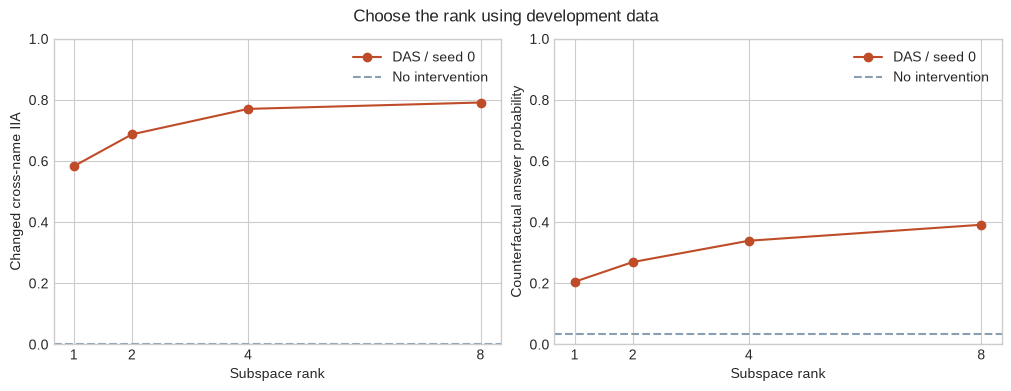

Frozen choice: 9 end 8


In [25]:
rank_fits, rank_results, rank_logits = {}, [], {}
for rank in (1, 2, 4, 8):
    fit = train_native_alignment(SELECTED_LAYER, SELECTED_POSITION, rank=rank, seed=0, steps=240)
    logits = evaluate_native_pairs(
        dev_cache, dev_interventions, SELECTED_LAYER, SELECTED_POSITION, fit["basis"]
    )
    metrics = native_metrics(logits, dev_interventions, dev_rows, name_ids, dev_cache.logits)
    rank_fits[rank], rank_logits[rank] = fit, logits
    rank_results.append(dict(rank=rank, metrics=metrics))
SELECTED_RANK = sorted(
    rank_results,
    key=lambda r: (
        -r["metrics"]["cross_changed"]["iia"],
        -r["metrics"]["cross_changed_target_probability"],
        r["rank"],
    ),
)[0]["rank"]

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), constrained_layout=True)
for ax, field, label in [
    (axes[0], "iia", "Changed cross-name IIA"),
    (axes[1], "probability", "Counterfactual answer probability"),
]:
    values = [
        r["metrics"]["cross_changed"]["iia"]
        if field == "iia"
        else r["metrics"]["cross_changed_target_probability"]
        for r in rank_results
    ]
    baseline = (
        dev_noop["cross_changed"]["iia"]
        if field == "iia"
        else dev_noop["cross_changed_target_probability"]
    )
    ax.plot([r["rank"] for r in rank_results], values, "o-", color="#bf4c28", label="DAS / seed 0")
    ax.axhline(baseline, color="#8a9eb2", linestyle="--", label="No intervention")
    ax.set(xlabel="Subspace rank", ylabel=label, xticks=[1, 2, 4, 8], ylim=(0, 1))
    ax.legend()
fig.suptitle("Choose the rank using development data")
fig.savefig(assets_dir / "das_native_rank_selection.png", dpi=160)
plt.show()
print("Frozen choice:", SELECTED_LAYER, SELECTED_POSITION, SELECTED_RANK)


# 6️⃣ Test the frozen hypothesis on new prompts

The prescribed development run selects block 9 input, final token, rank 8.
We now freeze the recipe: 240 updates, minibatch 16, learning rate .01. Keep
all three seeds 0, 1 and 2; train three matching shuffled-target controls and
retain all 32 random rank-eight subspaces. The observational ridge probe and
mean direction are fit from training activations only.

The final prompts use new templates and different name pairings. Half the
pairs contain a name absent from alignment training. Every native error stays
in the primary metric. We will also display the restricted denominator where
the base and explicit counterfactual are both natively correct, with its count.

If you change the preceding search or data as an exploration, treat your final
experiment as a new analysis. Do not keep consulting the same final set to
choose another method and still call it untouched evaluation.


In [26]:
from chapter11_representation_geometry.exercises.part3_causal_abstraction_das import (
    das_protocol as protocol,
)

assert (SELECTED_LAYER, SELECTED_POSITION, SELECTED_RANK) == (
    protocol.LAYER,
    protocol.POSITION,
    protocol.RANK,
), (
    "The prescribed development selection changed. Inspect it before applying the archived final protocol."
)
final_fits, final_bases = {}, {}
for seed in (0, 1, 2):
    for shuffled in (False, True):
        name = ("Shuffled" if shuffled else "DAS") + f"/seed{seed}"
        fit = train_native_alignment(
            SELECTED_LAYER, SELECTED_POSITION, SELECTED_RANK, seed, 240, shuffled
        )
        final_fits[name] = fit
        final_bases[name] = fit["basis"]

selected_activation = train_cache.activations(SELECTED_LAYER, SELECTED_POSITION)
roles = t.tensor([row["role"] for row in train_rows])
final_probe = fit_role_probe(selected_activation, roles)
mean_direction = selected_activation[roles == 1].mean(0) - selected_activation[roles == 0].mean(0)
final_bases["Role probe"] = final_probe["basis"]
final_bases["Mean direction"] = (mean_direction / mean_direction.norm())[:, None]
final_bases["No intervention"] = t.empty(768, 0)
for seed in protocol.RANDOM_SEEDS:
    final_bases[f"Random/seed{seed}"] = orthonormal_columns(
        t.randn(768, SELECTED_RANK, generator=t.Generator().manual_seed(seed))
    )
print(
    "All subspaces fitted using training data; all seeds retained. Opening final model evaluation now."
)

final_rows = ioi_data.prompt_rows("final")
final_interventions = ioi_data.interchange_pairs(final_rows)
final_cache = capture_native(gpt2, tokenizer, final_rows, layers=(SELECTED_LAYER,))
final_logits, final_metrics = {}, {}
for name, basis in final_bases.items():
    logits = evaluate_native_pairs(
        final_cache, final_interventions, SELECTED_LAYER, SELECTED_POSITION, basis
    )
    final_logits[name] = logits
    final_metrics[name] = native_metrics(
        logits, final_interventions, final_rows, name_ids, final_cache.logits
    )
full = evaluate_native_pairs(
    final_cache, final_interventions, SELECTED_LAYER, SELECTED_POSITION, whole_donor=True
)
final_logits["Whole donor"] = full
final_metrics["Whole donor"] = native_metrics(
    full, final_interventions, final_rows, name_ids, final_cache.logits
)
cf_indices = t.tensor([p["counterfactual"] for p in final_interventions])
final_logits["Explicit counterfactual"] = final_cache.logits[cf_indices]
final_metrics["Explicit counterfactual"] = native_metrics(
    final_cache.logits[cf_indices], final_interventions, final_rows, name_ids, final_cache.logits
)
assert weight_digest(gpt2) == native_weights_before
assert all(parameter.grad is None for parameter in gpt2.parameters())
print(
    f"Evaluated every one of {len(final_interventions)} final interventions; GPT-2 weights unchanged."
)


All subspaces fitted using training data; all seeds retained. Opening final model evaluation now.


Evaluated every one of 384 final interventions; GPT-2 weights unchanged.


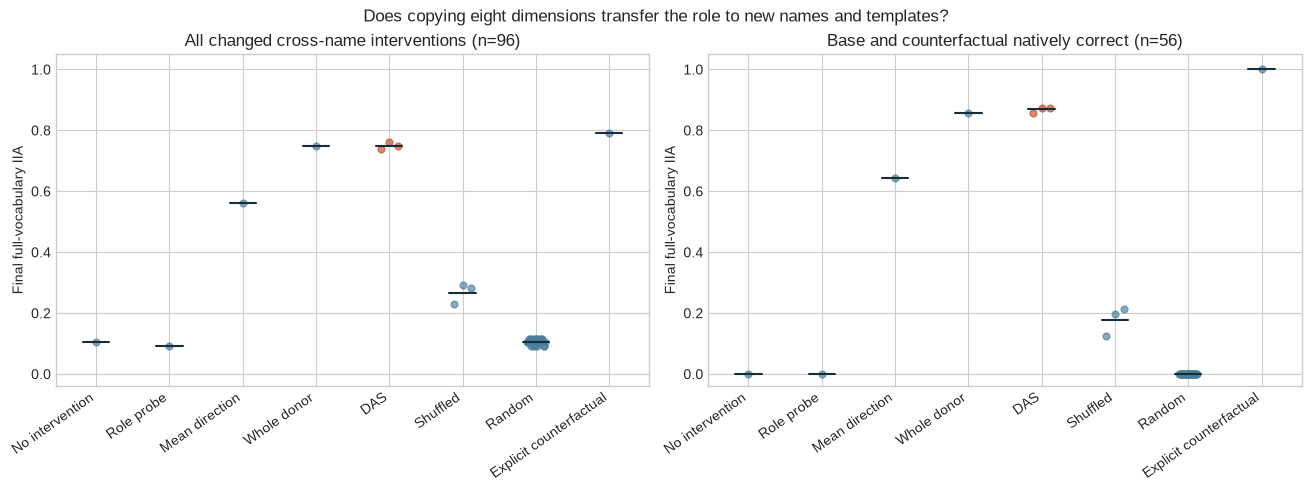

In [27]:
groups = [
    "No intervention",
    "Role probe",
    "Mean direction",
    "Whole donor",
    "DAS",
    "Shuffled",
    "Random",
    "Explicit counterfactual",
]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), constrained_layout=True)
for x, group in enumerate(groups):
    selected = [
        metric
        for name, metric in final_metrics.items()
        if name == group or name.startswith(group + "/")
    ]
    for ax, subgroup, title in [
        (axes[0], "cross_changed", "All changed cross-name interventions"),
        (axes[1], "both_native_correct_cross_changed", "Base and counterfactual natively correct"),
    ]:
        values = [metric[subgroup]["iia"] for metric in selected]
        count = selected[0][subgroup]["n"]
        jitter = np.linspace(-0.12, 0.12, len(values)) if len(values) > 1 else np.zeros(1)
        ax.scatter(
            x + jitter, values, color="#bf4c28" if group == "DAS" else "#487d9b", alpha=0.65, s=24
        )
        ax.plot([x - 0.18, x + 0.18], [np.mean(values)] * 2, color="#182c3a", linewidth=1.5)
        ax.set(
            title=title + f" (n={count})", ylim=(-0.04, 1.05), ylabel="Final full-vocabulary IIA"
        )
        ax.set_xticks(range(len(groups)), groups, rotation=35, ha="right")
fig.suptitle("Does copying eight dimensions transfer the role to new names and templates?")
fig.savefig(assets_dir / "das_native_final_controls.png", dpi=160)
plt.show()


<details><summary>Interpretation — which claim does this test support?</summary>

The three learned subspaces get **71/96, 73/96 and 72/96** changed cross-name
interventions correct. The whole-position donor gets **72/96** too. This run
supports a compact intervention with similar accuracy; it does not show that
DAS outperforms copying the whole residual vector. The mean direction reaches
54/96, the role probe 9/96, no intervention 10/96, and the best of all 32 random
rank-eight subspaces 11/96. Shuffled-target fits retain partial effects
(22/96, 28/96 and 27/96); they are not automatically inert.

Read the unconditional panel first. Each dot is one complete training seed or
random subspace, not a hand-picked prompt. A useful role intervention should
outperform no intervention and equal-rank random subspaces on changed cross-name
pairs. It should also preserve the intended answer when the source role is
unchanged. Shuffled supervision tests whether the training procedure can produce
a similar effect without the right counterfactual targets.

The conditional panel separates alignment failures from some native-model
failures. It uses fewer cases and answers a different question. Here its denominator is 56, with DAS
scores 48/56, 49/56 and 49/56. Its higher score cannot be substituted for the
primary result. The explicit counterfactual prompt achieves 76/96 overall;
that is an empirical native reference, not a mathematical upper bound on an
intervention trained toward the high-level answer. Even a good score does not prove
that all other variables are preserved, or that eight dimensions are a unique
or minimal implementation of the role.

</details>


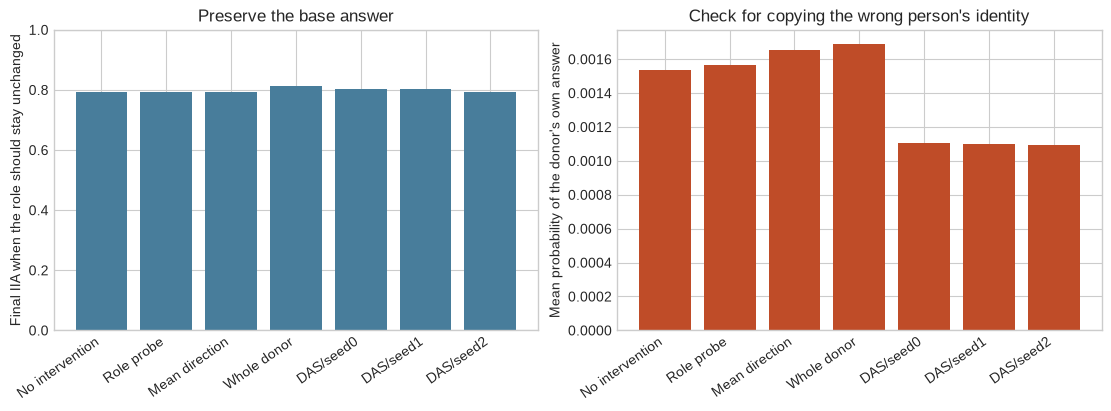

In [28]:
comparison = [
    "No intervention",
    "Role probe",
    "Mean direction",
    "Whole donor",
    "DAS/seed0",
    "DAS/seed1",
    "DAS/seed2",
]
fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
axes[0].bar(
    range(len(comparison)),
    [final_metrics[name]["cross_unchanged"]["iia"] for name in comparison],
    color="#487d9b",
)
axes[0].set(
    ylabel="Final IIA when the role should stay unchanged",
    ylim=(0, 1),
    title="Preserve the base answer",
)
axes[1].bar(
    range(len(comparison)),
    [final_metrics[name]["cross_donor_answer_probability"] for name in comparison],
    color="#bf4c28",
)
axes[1].set(
    ylabel="Mean probability of the donor's own answer",
    title="Check for copying the wrong person's identity",
)
for ax in axes:
    ax.set_xticks(range(len(comparison)), comparison, rotation=35, ha="right")
fig.savefig(assets_dir / "das_native_specificity.png", dpi=160)
plt.show()


## Inspect where the held-out result transfers

Break down the already frozen final results by template and by whether the
**base names** appeared in alignment training. This is a descriptive diagnosis;
we do not use it to refit or select another model. The 96 cross-name, changed-role
pairs share names and templates, so do not treat them as 96 independent draws
from all possible language. The orange error bars span the three seeds; they
are not statistical confidence intervals.


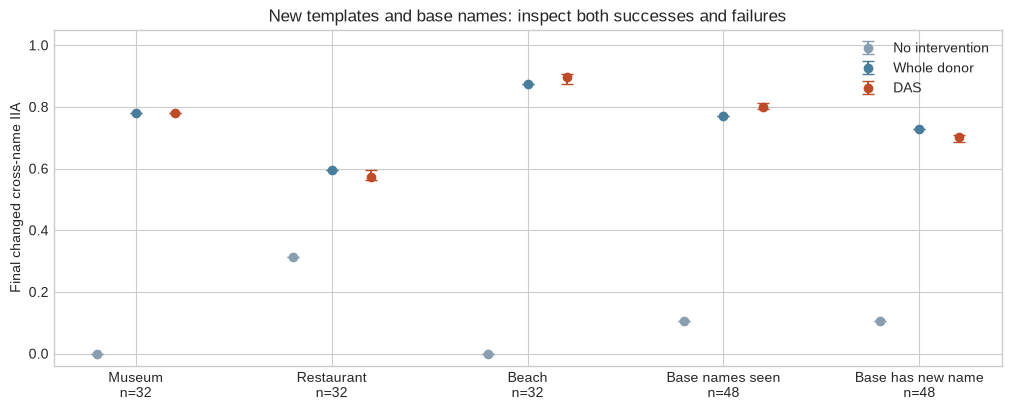

In [29]:
changed_cross = t.tensor(
    [pair["cross_name"] and pair["changed_role"] for pair in final_interventions]
)
final_targets = t.tensor([name_ids[pair["target"]] for pair in final_interventions])
base_template = t.tensor([final_rows[pair["base"]]["template"] for pair in final_interventions])
base_seen = t.tensor(
    [final_rows[pair["base"]]["names_seen_in_training"] for pair in final_interventions]
)
subgroups = [
    ("Museum", changed_cross & (base_template == 0)),
    ("Restaurant", changed_cross & (base_template == 1)),
    ("Beach", changed_cross & (base_template == 2)),
    ("Base names seen", changed_cross & base_seen),
    ("Base has new name", changed_cross & ~base_seen),
]
fig, ax = plt.subplots(figsize=(10, 4), constrained_layout=True)
for offset, method, color in [
    (-0.2, "No intervention", "#8a9eb2"),
    (0, "Whole donor", "#487d9b"),
    (0.2, "DAS", "#bf4c28"),
]:
    names = [f"DAS/seed{seed}" for seed in (0, 1, 2)] if method == "DAS" else [method]
    values = np.array(
        [
            [interchange_accuracy(final_logits[name], final_targets, mask) for _, mask in subgroups]
            for name in names
        ]
    )
    average = values.mean(0)
    errors = np.stack([average - values.min(0), values.max(0) - average])
    ax.errorbar(
        np.arange(len(subgroups)) + offset,
        average,
        yerr=errors,
        fmt="o",
        capsize=4,
        color=color,
        label=method,
    )
ax.set_xticks(
    range(len(subgroups)), [label + chr(10) + f"n={int(mask.sum())}" for label, mask in subgroups]
)
ax.set(
    ylim=(-0.04, 1.05),
    ylabel="Final changed cross-name IIA",
    title="New templates and base names: inspect both successes and failures",
)
ax.legend()
fig.savefig(assets_dir / "das_native_generalization.png", dpi=160)
plt.show()


## Signature result: inspect actual next-token distributions

These three examples were chosen by row order before final-model execution:
the first changed cross-name pair in each template. They include whichever
successes and failures the model produces. For each, inspect both the desired
base answer and the donor's own answer. The last column combines all vocabulary
items other than these four names, so each row still sums to one. Each row label
also gives the model's actual top token. This matters in the restaurant example:
the explicit counterfactual prompt predicts ` the`, while the DAS intervention
predicts the high-level answer ` Mary`. A high-level task score and exact recovery
of a native counterfactual distribution measure different things.


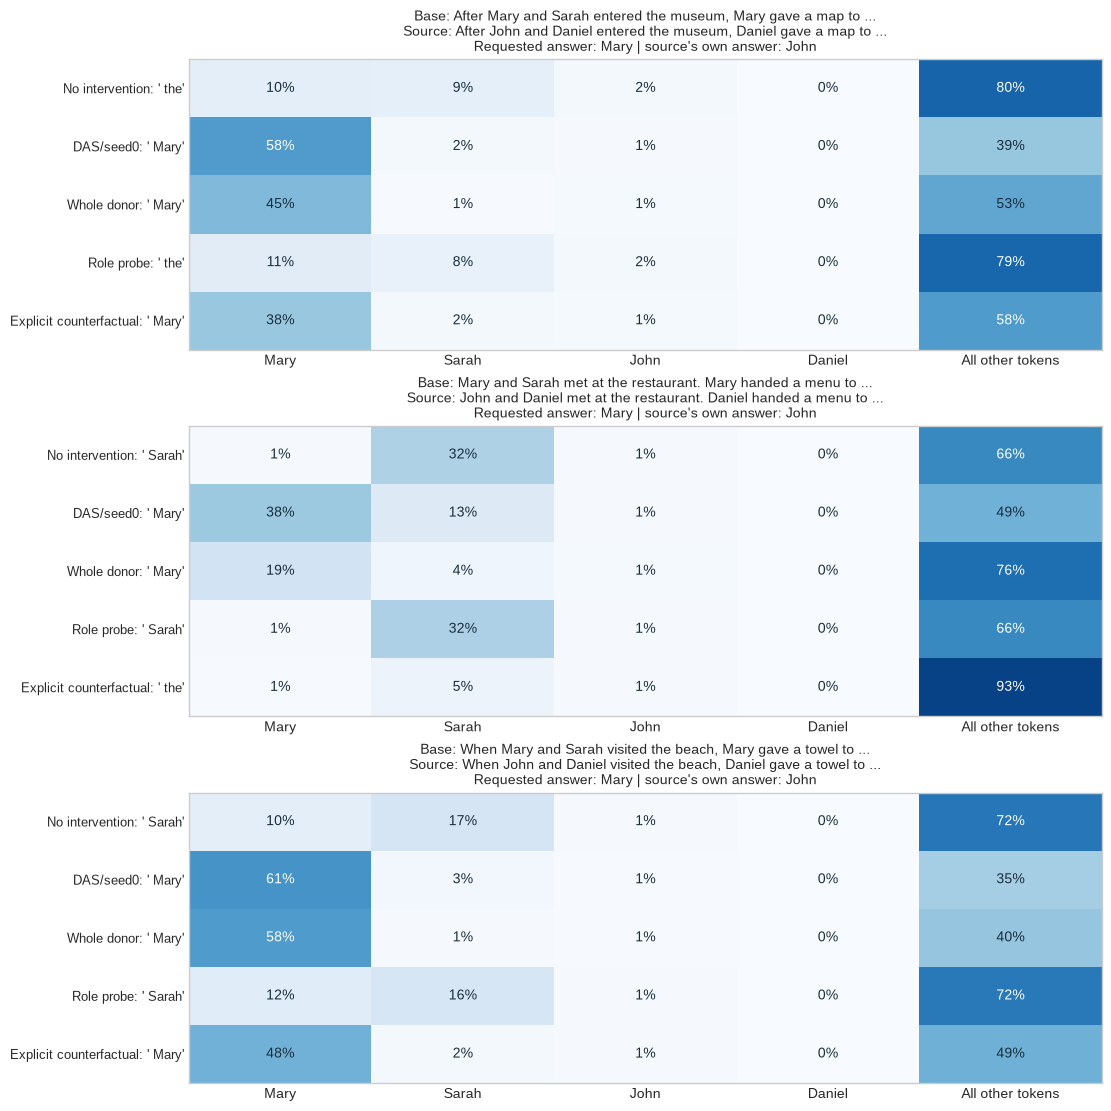

In [30]:
fixed_examples = [
    next(
        i
        for i, pair in enumerate(final_interventions)
        if pair["cross_name"]
        and pair["changed_role"]
        and final_rows[pair["base"]]["template"] == template
    )
    for template in protocol.DISPLAY_TEMPLATE_IDS
]
shown_methods = [
    "No intervention",
    "DAS/seed0",
    "Whole donor",
    "Role probe",
    "Explicit counterfactual",
]
fig, axes = plt.subplots(3, 1, figsize=(11, 11), constrained_layout=True)
for ax, pair_index in zip(axes, fixed_examples):
    pair = final_interventions[pair_index]
    base, source = final_rows[pair["base"]], final_rows[pair["source"]]
    names = [base["a"], base["b"], source["a"], source["b"]]
    ids = t.tensor([name_ids[name] for name in names])
    matrix = []
    for method in shown_methods:
        probabilities = final_logits[method][pair_index].softmax(-1)
        selected = probabilities[ids]
        matrix.append(t.cat([selected, (1 - selected.sum()).reshape(1)]).numpy())
    matrix = np.array(matrix)
    ax.imshow(matrix, cmap="Blues", vmin=0, vmax=1, aspect="auto")
    for row in range(len(shown_methods)):
        for col in range(5):
            ax.text(
                col,
                row,
                f"{matrix[row, col]:.0%}",
                ha="center",
                va="center",
                color="white" if matrix[row, col] > 0.55 else "#182c3a",
            )
    ax.set_xticks(range(5), names + ["All other tokens"])
    winning_labels = [
        method + ": " + repr(tokenizer.decode([int(final_logits[method][pair_index].argmax())]))
        for method in shown_methods
    ]
    ax.set_yticks(range(len(shown_methods)), winning_labels, fontsize=9)
    ax.grid(False)
    ax.set_title(
        f"Base: {base['prompt']} ..."
        + chr(10)
        + f"Source: {source['prompt']} ..."
        + chr(10)
        + f"Requested answer: {pair['target']} | source's own answer: {source['answer']}",
        fontsize=10,
    )
fig.savefig(assets_dir / "das_native_token_examples.png", dpi=160)
plt.show()


## Try It Yourself — change the donor's role

Choose a base row and a source row, then rerun the native intervention. Keep
track of the first two names and the repeated-name role in each prompt. The
requested answer must come from the base's names. Compare a learned subspace,
whole-position replacement and a random subspace of the same rank.

Try both a source with the same role and a source with the opposite role.
Change the donor's names too. A successful example is useful for understanding
the operation, but it does not replace the complete final evaluation above.


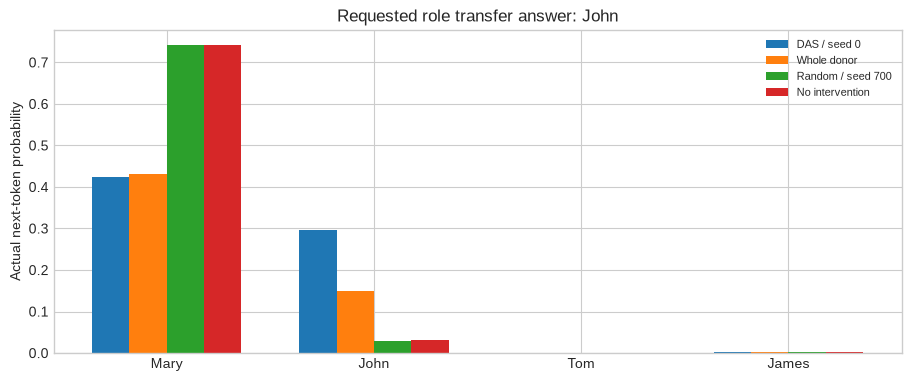

Base: While Mary and John were at the school, John gave a pen to
Source: While Tom and James were at the school, Tom gave a pen to


In [31]:
PLAY_BASE_INDEX, PLAY_SOURCE_INDEX = 1, 4
play_base, play_source = dev_rows[PLAY_BASE_INDEX], dev_rows[PLAY_SOURCE_INDEX]
play_pair = dict(base=PLAY_BASE_INDEX, source=PLAY_SOURCE_INDEX)
play_target = (play_base["a"], play_base["b"])[1 - play_source["role"]]
play_distributions = {}
for method, basis, whole in [
    ("DAS / seed 0", final_bases["DAS/seed0"], False),
    ("Whole donor", None, True),
    ("Random / seed 700", final_bases["Random/seed700"], False),
    ("No intervention", final_bases["No intervention"], False),
]:
    play_distributions[method] = evaluate_native_pairs(
        dev_cache, [play_pair], SELECTED_LAYER, SELECTED_POSITION, basis, whole
    )[0].softmax(-1)
play_names = list(
    dict.fromkeys([play_base["a"], play_base["b"], play_source["a"], play_source["b"]])
)
fig, ax = plt.subplots(figsize=(9, 3.7), constrained_layout=True)
for method_index, (method, probabilities) in enumerate(play_distributions.items()):
    ax.bar(
        np.arange(len(play_names)) + (method_index - 1.5) * 0.18,
        [float(probabilities[name_ids[name]]) for name in play_names],
        width=0.18,
        label=method,
    )
ax.set_xticks(range(len(play_names)), play_names)
ax.set(
    ylabel="Actual next-token probability", title=f"Requested role transfer answer: {play_target}"
)
ax.legend(fontsize=8)
fig.savefig(assets_dir / "das_native_pair_play.png", dpi=160)
plt.show()
print("Base:", play_base["prompt"])
print("Source:", play_source["prompt"])


## Keep the complete evidence

The notebook's figures are the teaching results. The following cell additionally
saves all candidate parameters, actual full-vocabulary outputs, pair identities
and training histories so the calculations can be audited and reproduced.
The larger tensor file belongs in your output directory, not in the repository.
Saving it does not substitute for the experiments you just ran.


In [32]:
import json

native_summary = dict(
    scope="pretrained_GPT2_role_interchange",
    model_id=ioi_data.MODEL_ID,
    revision=ioi_data.REVISION,
    selected=dict(layer=SELECTED_LAYER, position=SELECTED_POSITION, rank=SELECTED_RANK),
    train_prompts=len(train_rows),
    development_prompts=len(dev_rows),
    final_prompts=len(final_rows),
    final_pairs=len(final_interventions),
    final_metrics=final_metrics,
    site_results=site_results,
    rank_results=rank_results,
    weights_sha256=native_weights_before,
    weights_unchanged=weight_digest(gpt2) == native_weights_before,
    model_gradients_absent=all(parameter.grad is None for parameter in gpt2.parameters()),
    fixed_example_indices=fixed_examples,
    native_path_checks=native_path_checks,
)
(assets_dir / "native_summary.json").write_text(json.dumps(native_summary, indent=2) + chr(10))
t.save(
    dict(
        train_rows=train_rows,
        development_rows=dev_rows,
        final_rows=final_rows,
        train_pairs=train_interventions,
        development_pairs=dev_interventions,
        final_pairs=final_interventions,
        train_logits=train_cache.logits,
        development_logits=dev_cache.logits,
        native_final_logits=final_cache.logits,
        final_logits=final_logits,
        final_fits=final_fits,
        final_bases=final_bases,
        site_fits=site_fits,
        site_logits=site_logits,
        rank_fits=rank_fits,
        rank_logits=rank_logits,
        final_activations=final_cache.activations(SELECTED_LAYER, SELECTED_POSITION),
        native_weights_sha256=native_weights_before,
    ),
    assets_dir / "actual_native_tensors.pt",
)
print("Saved every candidate, seed, control and actual native output.")


Saved every candidate, seed, control and actual native output.


## Limitations and further investigations

This exact model was constructed to have two independent causal coordinates.
The unused duplicate also creates redundancy: more than one subspace can
implement the same output changes. The finite 1,024-pair test covers every
binary setting with new nuisance values, not every continuous hidden state.
An intervention can violate the observational equality between used and copied
coordinates; that does not by itself invalidate the specified structural
intervention. It does limit what an observational-manifold argument can prove.

The GPT-2 experiment tests a finite name-role intervention distribution, with
new templates and name pairings. Template and name reuse makes the individual
interventions statistically dependent; seed spread is descriptive, not a
confidence interval over every possible sentence. The high-level grammar is
intentionally small, and output agreement does not test all intermediate
variables or arbitrary off-distribution edits. Training an alignment is also
distinct from training the neural model itself with an interchange objective.

For further work, specify a new intervention distribution before training: swap
a different high-level variable, use more varied sentence structures, or test
whether two independently learned variable interventions commute. Predict which
controls should remain strong and which failure would change your explanation.

## Reading

- [Geiger et al., Finding Alignments Between Interpretable Causal Variables and Distributed Neural Representations](https://proceedings.mlr.press/v236/geiger24a.html): DAS and distributed interchange interventions. Our thin QR basis implements one orthogonal subspace rather than optimizing a full square rotation.
- [Geiger et al., Causal Abstraction: A Theoretical Foundation for Mechanistic Interpretability](https://jmlr.org/papers/v26/23-0058.html): formal alignments, intervention distributions and approximate abstraction. An empirical output score supplies only part of that argument.
